In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.optimize import minimize
from scipy.optimize import approx_fprime
from scipy.linalg import solve_triangular
from joblib import Parallel, delayed
from matplotlib.ticker import ScalarFormatter

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

import importlib
import Hippocampal as HP
import HippocampalJAX as HPJ
importlib.reload(HP)
importlib.reload(HPJ)

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
cmap2 = plt.cm.twilight
rng = np.random.default_rng(seed=12345)   # PCG64 by default
cm = 1 / 2.54

# Model

## Load data


In [5]:
n_channels = 31
fs = 1250 # Hz

path = 'data/'
file = 'ec013.527.eeg'
x = np.fromfile(path+file, dtype=np.int16)
x = x.reshape(-1, n_channels)

signal = x[:,5]      # sixth channel
time = np.arange(len(signal))/fs
print(time.shape[0])

1325125


### Plot dense data

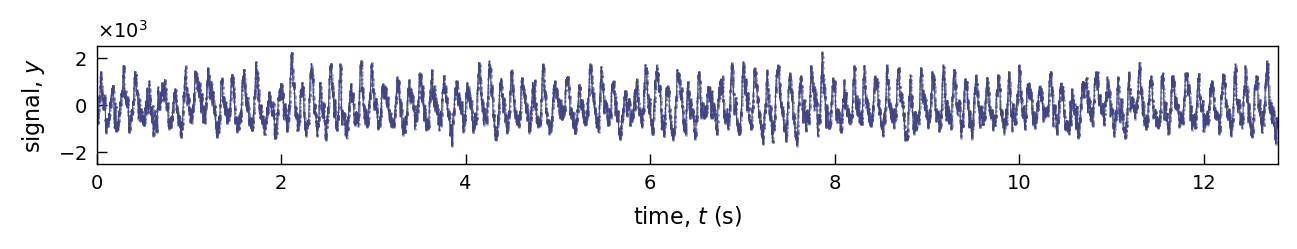

In [6]:
imin = 10000
istep = 1
Nmax = 16000
imax = imin + istep*Nmax

tk = time[imin:imax:istep] - time[imin]
yk = signal[imin:imax:istep]
dtmin = np.diff(tk).mean()

# fixed axis geometry
ax_h = 1.5 * cm
ax_w = 15 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

ax.plot(tk, yk,  '-', c=cmap(0.2), lw=0.4)
ax.plot(tk, yk,  '.', alpha=0.5, c=cmap(0.2), mew=0, ms=2)
ax.set_xlim(tk[0], tk[-1])
ax.set_ylim(-2500, 2500)
ax.yaxis.set_major_formatter(formatter)
ax.yaxis.get_offset_text().set_fontsize(7)

ax.set_xlabel('time, $t$ (s)', fontsize=8)
ax.set_ylabel('signal, $y$', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalTrace.pdf')

In [7]:
dtmin

np.float64(0.0007999999999999999)

### Plot thinned data

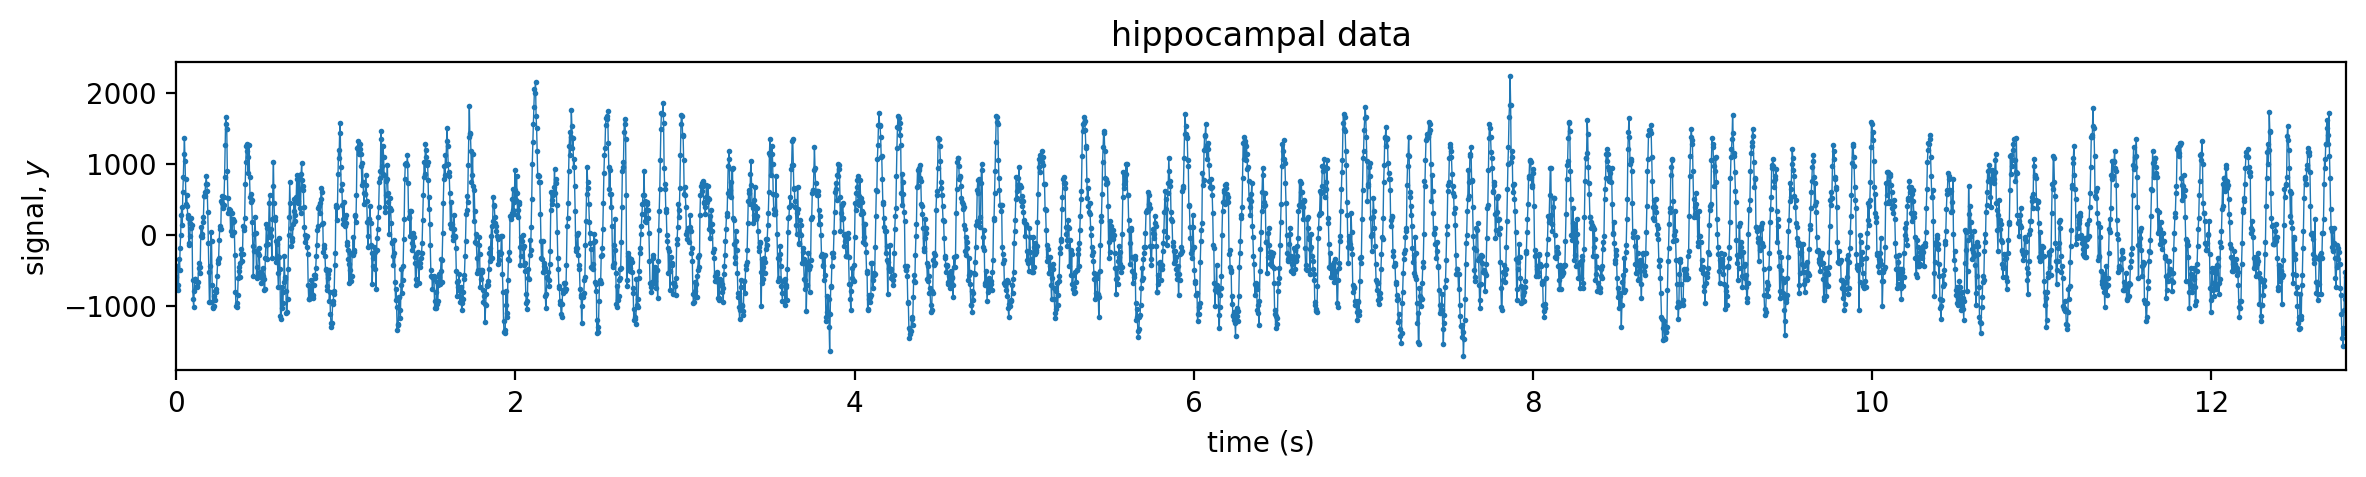

In [8]:
istep = 4 # 16
N = np.round(Nmax / istep).astype(int)
imax = imin + istep*N

tk = time[imin:imax:istep] - time[imin]
yk = signal[imin:imax:istep]
N = tk.shape[0]
dt = np.diff(tk).mean()

# Create figure with computed size
fig = plt.figure(figsize=(14, 2))

plt.plot(tk, yk,  '.-', lw=0.5, ms=2)
plt.xlim(tk[0], tk[-1])
plt.xlabel('time (s)')
plt.ylabel('signal, $y$')
plt.title('hippocampal data');

## Add Regularizing Noise

In [9]:
# R_add = 5.0e4 # regularizing noise magnitude BAD
R_add = 1.0e6 # regularizing noise magnitude GOOD
data = (tk, yk)
rng = np.random.default_rng(seed=12345)   # PCG64 by default

tk, yk_reg = HP.add_regularizing_noise(data, R_add, rng)
data_reg = (tk, yk_reg)

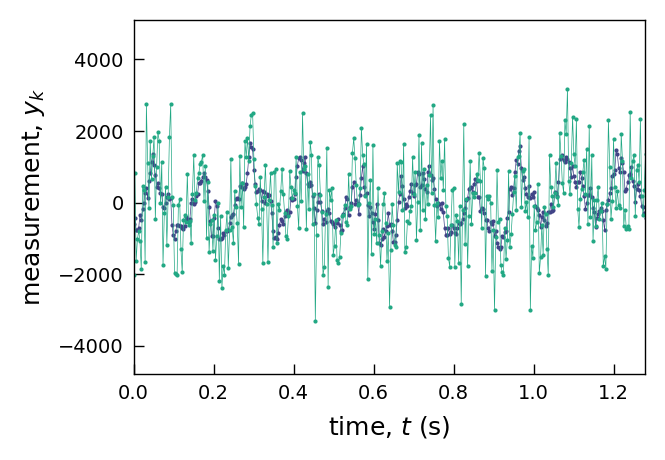

In [11]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, yk, '.-', lw=0.25, mew=0, ms=3, color=cmap(0.2), label='$y_1$')
ax.plot(tk, yk_reg, '.-', lw=0.25, mew=0, ms=3, color=cmap(0.6))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$ (s)', fontsize=9)
ax.set_ylabel(r'measurement, $y_k$', fontsize=9)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')
# ax.set_yticks([0, 1, 2, 3])

# Set the x-axis limits from 0 to 2000
# ax.set_xlim(tk[0], tk[-1])
ax.set_xlim(tk[0], tk[-1] - 0.9*(tk[-1]-tk[0]))
# ax.set_ylim(0, xmax)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plotsHippocampalTraceNoise.pdf')

## Estimate frequency

In [12]:
omega_FFT, _ , _ = HP.estimate_frequency_fft(data)
print(f'Frequency estimate = {omega_FFT:.5f}')

Frequency estimate = 52.40078


## Estimate initial phase

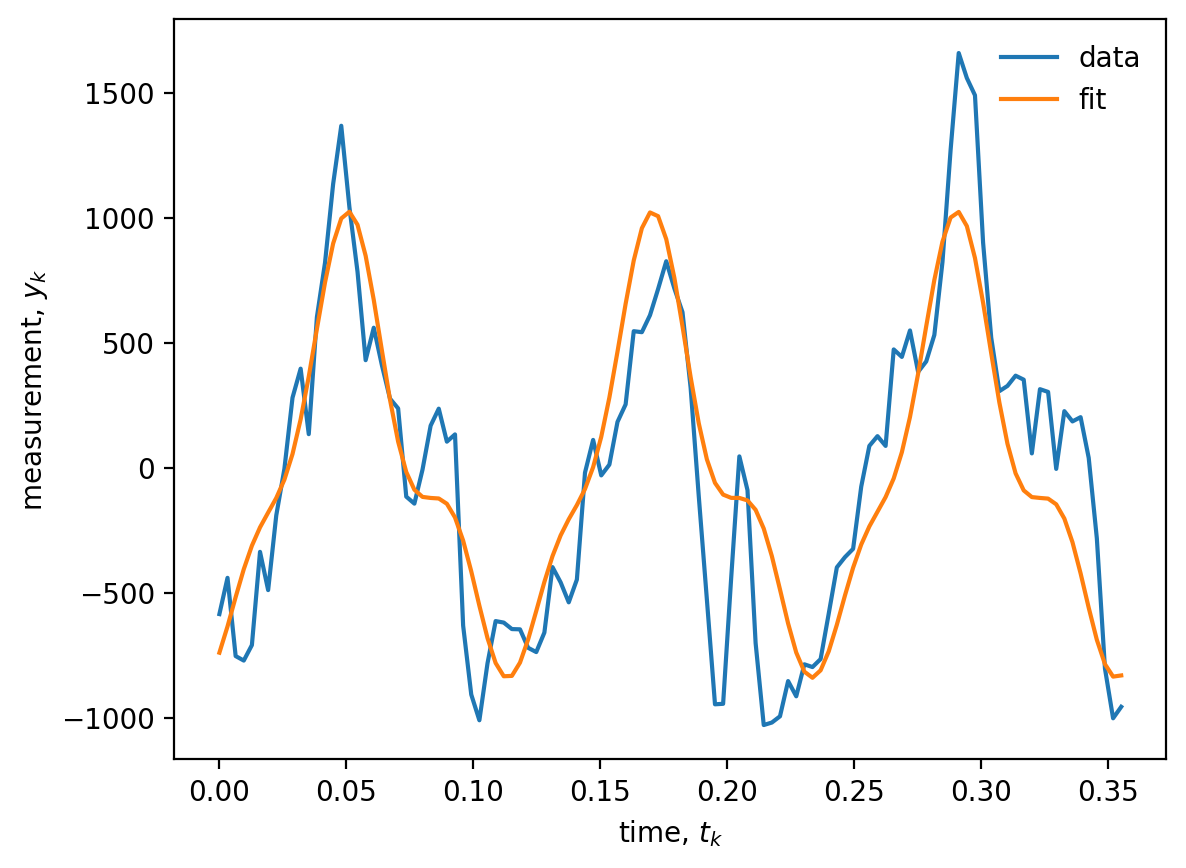

In [13]:
M = 3          # number of Fourier modes
window_size = int(3 * 2*np.pi / (omega_FFT * dt))   # select the window used for initialization
phase_init = HP.estimate_initial_phase_regression(data, omega_FFT, window_size, R_add, M=M)

plt.plot(tk[0:window_size], yk[0:window_size], label='data')
plt.plot(tk[0:window_size], phase_init['y_fit'], label='fit')
plt.legend(frameon=False)
plt.xlabel('time, $t_k$')
plt.ylabel('measurement, $y_k$');

## Priors $p(\lambda)$

In [14]:
# state priors
mu_theta = phase_init["phi_mean"] + omega_FFT * tk[0]
sigma_theta = 2 * phase_init["phi_std"] # inflate by 2 to be cautious
state_priors = (mu_theta, sigma_theta)

# parameter priors 
mu_omega = omega_FFT
sigma_omega = 1.0     # <== INPUT
Dtheta_mode = 2.0     # <== INPUT   
alpha_D = 1.0         # Laplace variance 1/alpha
beta_D = alpha_D*Dtheta_mode  # mode = alpha/beta for log parameterization
R_mode = 1000 # R_add
alpha_R = 1.0                 # Laplace variance 1/alpha
beta_R = alpha_R*R_mode       # mode = alpha/beta for log parameterization
mu_A = 0.0
sigma_A = yk.mean()
sigma_q = yk.std()

param_priors = (mu_omega, sigma_omega, 
                alpha_D, beta_D, 
                alpha_R, beta_R, 
                mu_A, sigma_A,
                sigma_q)

priors = state_priors + param_priors

# Estimating parameters, $p(\lambda \mid y_{1:N})$

## Optimization of $\log p(\lambda \mid y)$ 

### Gradient-free optimizer (SLOW AND UNNECESSARY)

We can optimize $-\log p(\lambda\mid y)$ directly using a gradient free optimizer like Powell or Nelder-Mead.

In [15]:
n_theta = 256

def objective(x):
    try:
        val = HP.neg_log_posterior(
            HP.unpack_param(x, M),
            data_reg,
            priors,
            n_theta=n_theta,
        )

        if not np.isfinite(val):
            return BAD

        return val

    except (FloatingPointError, RuntimeError, ValueError, OverflowError):
        return BAD

iter_count = {"k": 0}

def callback(xk):
    iter_count["k"] += 1

    omega, lnDtheta, lnR, A, B = HP.unpack_param(xk, M)

    print(
        f"{iter_count['k']:4d}  "
        f"omega={omega:.6f}  "
        f"lnDtheta={lnDtheta:.6f}  "
        f"lnR={lnR:.6f}"
    )

In [16]:
%%time

param0 = HP.pack_param(
    omega_FFT,
    np.log(Dtheta_mode),
    np.log(R_add),
    phase_init["A"],
    phase_init["B"],
)

res = minimize(
    fun=objective,
    x0=param0,
    method="Powell",
    callback=callback,
)

print(res, "\n")

   1  omega=51.822103  lnDtheta=1.065185  lnR=13.914883
   2  omega=51.897143  lnDtheta=0.893934  lnR=13.893984
 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 33649.31161191957
       x: [ 5.190e+01  8.939e-01  1.389e+01 -1.022e+00  8.802e+02
            1.783e+02  6.036e+01 -2.066e+02 -1.104e+02]
     nit: 2
   direc: [[ 1.000e+00  0.000e+00 ...  0.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00 ...  0.000e+00  0.000e+00]
           ...
           [ 0.000e+00  0.000e+00 ...  1.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00 ...  0.000e+00  1.000e+00]]
    nfev: 165 

CPU times: user 16.8 s, sys: 356 ms, total: 17.1 s
Wall time: 17.4 s


In [17]:
lambda_map = HP.unpack_param(res.x, M)
lambda_map

(np.float64(51.897143266450016),
 np.float64(0.8939337380450576),
 np.float64(13.893983980420641),
 array([ -1.02228355, 880.18190209, 178.28348079,  60.35795474]),
 array([   0.        ,    0.        , -206.60853452, -110.44173349]))

### JAX-based optimizer

In [18]:
x0 = jnp.asarray(param0)
tk_jax = jnp.asarray(data_reg[0])
yk_jax = jnp.asarray(data_reg[1])
priors_jax = tuple(jnp.asarray(p) for p in priors)

In [19]:
val_np = objective(np.asarray(param0))

val_jax = HPJ.neg_log_posterior_flat_jit(
    x0,
    tk_jax,
    yk_jax,
    priors_jax,
    M=M,
    n_theta=n_theta,
)

print(val_np)
print(float(val_jax))
print(float(val_jax - val_np))

33696.37319630701
33696.37319631151
4.503817763179541e-09


In [20]:
g_jax = HPJ.grad_neg_log_posterior_flat_jit(
    x0,
    tk_jax,
    yk_jax,
    priors_jax,
    M=M,
    n_theta=n_theta,
)

print(np.asarray(g_jax))
print("gradient norm:", float(jnp.linalg.norm(g_jax)))

[ 2.40861574e+00 -1.33191929e+01 -2.12405949e+02 -1.98668870e-01
 -2.52891543e-01 -1.25753219e-01  4.78484578e-02  1.27079574e-01
  6.21324743e-02]
gradient norm: 212.83709978970094


In [21]:
%%time

def objective_jax_np(x):
    return float(HPJ.neg_log_posterior_flat_jit(
        jnp.asarray(x),
        tk_jax,
        yk_jax,
        priors_jax,
        M=M,
        n_theta=n_theta,
    ))

def grad_jax_np(x):
    return np.asarray(HPJ.grad_neg_log_posterior_flat_jit(
        jnp.asarray(x),
        tk_jax,
        yk_jax,
        priors_jax,
        M=M,
        n_theta=n_theta,
    ))

res_jax = minimize(
    objective_jax_np,
    np.asarray(param0),
    jac=grad_jax_np,
    method="BFGS",
    options=dict(
        maxiter=500,
        gtol=1e-3,
    ),
)

print(res_jax)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 33649.304590138316
        x: [ 5.187e+01  8.852e-01  1.390e+01 -1.009e+00  8.798e+02
             1.763e+02  5.790e+01 -2.067e+02 -1.105e+02]
      nit: 63
      jac: [-1.231e-05  2.486e-04  4.308e-05 -6.831e-07  9.067e-06
             2.022e-04 -2.438e-04  2.556e-04  1.436e-04]
 hess_inv: [[ 2.901e-01  9.363e-03 ...  7.523e-02  1.709e-01]
            [ 9.363e-03  3.350e-02 ...  4.945e-01  2.788e-01]
            ...
            [ 7.523e-02  4.945e-01 ...  7.419e+02 -1.887e+02]
            [ 1.709e-01  2.788e-01 ... -1.887e+02  1.333e+03]]
     nfev: 68
     njev: 68
CPU times: user 8.4 s, sys: 767 ms, total: 9.17 s
Wall time: 7.8 s


In [22]:
lambda_map_jax = HP.unpack_param(res_jax.x, M)
omega_map = lambda_map_jax[0]
lnDtheta_map = lambda_map_jax[1]

compare = pd.DataFrame([
    HP.summarize_map(lambda_map, prefix=""),
    HP.summarize_map(lambda_map_jax, prefix=""),
], index=["NumPy Powell", "JAX BFGS"])

compare[["omega", "lnDtheta", "Dtheta", "lnR", "R_eff", "M"]]

,omega,lnDtheta,Dtheta,lnR,R_eff,M
NumPy Powell,51.897143,0.893934,2.444728,13.893984,1.081635e+06,3
JAX BFGS,51.868293,0.885175,2.423410,13.895557,1.083337e+06,3


In [23]:
x_np = HP.pack_param(*lambda_map)
x_jax = HP.pack_param(*lambda_map_jax)

diff = pd.DataFrame({
    "numpy": x_np,
    "jax": x_jax,
    "diff": x_jax - x_np,
    "rel_diff": (x_jax - x_np) / np.maximum(np.abs(x_np), 1e-12),
})

diff

,numpy,jax,diff,rel_diff
0,51.897143,51.868293,-0.028850,-0.000556
1,0.893934,0.885175,-0.008758,-0.009797
2,13.893984,13.895557,0.001573,0.000113
3,-1.022284,-1.009333,0.012951,0.012668
4,880.181902,879.792333,-0.389569,-0.000443
5,178.283481,176.304123,-1.979358,-0.011102
6,60.357955,57.900398,-2.457557,-0.040716
7,-206.608535,-206.741182,-0.132648,-0.000642
8,-110.441733,-110.479067,-0.037333,-0.000338


In [24]:
print("NumPy/Powell objective:", objective(x_np))
print("JAX/BFGS objective:    ", objective(x_jax))
print("difference:", objective(x_jax) - objective(x_np))

NumPy/Powell objective: 33649.31161191957
JAX/BFGS objective:     33649.30459013438
difference: -0.007021785189863294


## Uncertainty quantification

### JAX Hessian

In [25]:
%%time

H_direct = np.asarray(
    HPJ.hessian_neg_log_posterior_flat_jit(
        x_jax,
        tk_jax,
        yk_jax,
        priors_jax,
        M=M,
        n_theta=n_theta,
    )
)

H_direct = 0.5 * (H_direct + H_direct.T)

eig = np.linalg.eigvalsh(H_direct)

print("min eig:", eig[0])
print("max eig:", eig[-1])
print("condition:", eig[-1] / eig[0])
print("finite:", np.all(np.isfinite(H_direct)))

min eig: 0.00048684343700651527
max eig: 1873.4884961527941
condition: 3848236.1140008997
finite: True
CPU times: user 3.27 s, sys: 371 ms, total: 3.64 s
Wall time: 1.63 s


In [26]:
%%time

H_fd = HPJ.hessian_neg_log_posterior_fd(
    x_jax,
    tk_jax,
    yk_jax,
    priors_jax,
    M=M,
    n_theta=n_theta,
)

H_fd = 0.5 * (H_fd + H_fd.T)

eig = np.linalg.eigvalsh(H_fd)

print("min eig:", eig[0])
print("max eig:", eig[-1])
print("condition:", eig[-1] / eig[0])
print("finite:", np.all(np.isfinite(H_fd)))

min eig: 0.0004868434366958411
max eig: 1873.4889933798297
condition: 3848237.1377850273
finite: True
CPU times: user 1.55 s, sys: 225 ms, total: 1.78 s
Wall time: 1.39 s


In [27]:
cov = np.linalg.inv(H_direct)
se = np.sqrt(np.diag(cov))

omega_se = se[0]
lnDtheta_se = se[1]

In [28]:
evals, evecs = np.linalg.eigh(H_direct)

names = (
    ["omega", "lnDtheta", "lnR"]
    + [f"A{m}" for m in range(M + 1)]
    + [f"B{m}" for m in range(2, M + 1)]
)

soft = evecs[:, 0]

for name, weight in sorted(zip(names, soft), key=lambda x: -abs(x[1])):
    print(f"{name:10s} {weight:+.3f}")

B3         +0.731
A3         +0.639
B2         +0.162
A2         +0.160
A1         +0.070
A0         +0.001
lnDtheta   +0.000
omega      -0.000
lnR        -0.000


### Save parameter estimates

In [91]:
parameter_estimates_path = 'data/parameter_estimates_good.npz'
np.savez(
    parameter_estimates_path,
    map_estimate=np.asarray(x_jax),
    laplace_covariance=np.asarray(cov),
    parameter_names=np.asarray(names),
)
print(f'Saved MAP estimate and Laplace covariance to {parameter_estimates_path}')

Saved MAP estimate and Laplace covariance to data/parameter_estimates_good.npz


### Marginal Distributions

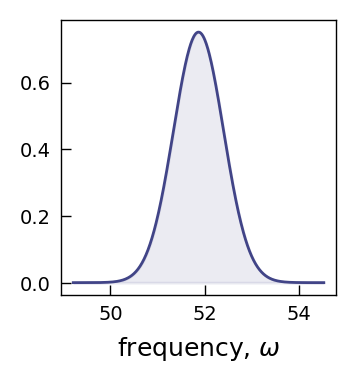

In [29]:
omega = omega_map
omegas = np.linspace(omega_map-5*omega_se, omega_map+5*omega_se, 500)
pdf = stats.norm.pdf(omegas, loc=omega_map, scale=omega_se)

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(omegas,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(omegas,pdf,alpha=0.1,color=cmap(0.2))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'frequency, $\omega$', fontsize=9)

# Create legend (frame turned off)
# ax.legend(frameon=False, fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

# plt.savefig('GO_Frequency.pdf')

2.4234095623601526
1.0000016961920934


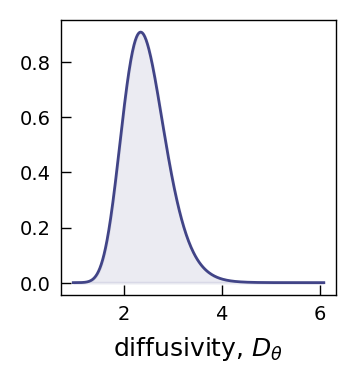

In [30]:
Dtheta = np.exp(lnDtheta_map)
lnDthetas = np.linspace(lnDtheta_map-5*lnDtheta_se, lnDtheta_map+5*lnDtheta_se, 500)
Dthetas = np.exp(lnDthetas)
pdf = stats.lognorm.pdf(Dthetas, s=lnDtheta_se, scale=np.exp(lnDtheta_map))
print(np.exp(lnDtheta_map))
print(np.trapezoid(pdf, Dthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 3.5
axes_height_cm = 3.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
plt.plot(Dthetas,pdf,color=cmap(0.2), label='true', lw=1)
plt.fill_between(Dthetas,pdf,alpha=0.1,color=cmap(0.2))

# Set axis labels with font size 9 pt
ax.set_xlabel(r'diffusivity, $D_\theta$', fontsize=9)
# ax.set_xscale('log')

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

# plt.savefig('GO_Diffusivity.pdf')

1.0000011223908352
0.9999988523994123


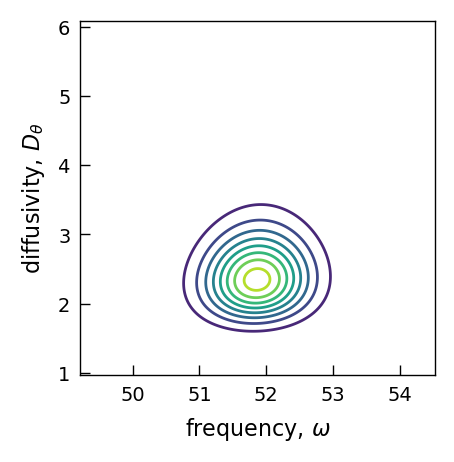

In [31]:
OMEGAS, LNDTHETAS = np.meshgrid(omegas, lnDthetas)

pos = np.dstack((OMEGAS, LNDTHETAS))
DTHETAS = np.exp(LNDTHETAS)

# evaluate pdf
rv = stats.multivariate_normal(np.array([omega_map, lnDtheta_map]), cov[:2,:2])
Z = rv.pdf(pos)
print(np.trapezoid(np.trapezoid(Z / DTHETAS, omegas), Dthetas))
print(np.trapezoid(np.trapezoid(Z, omegas), lnDthetas))

# Desired axes dimensions in centimeters
axes_width_cm = 4.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.5
right_margin = 0.5
bottom_margin = 0.5
top_margin = 0.5

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# plot
plt.contour(OMEGAS, DTHETAS, Z / DTHETAS, levels=10, linewidths=1)
# plt.plot(omega_map, np.exp(lnDtheta_map), 'kx', ms=3)

# Dtheta_PR = 0.00648472
# plt.axhline(y=Dtheta_PR, color='k', ls='--', lw=0.5)
# plt.axvline(x=omega0, color='k', ls='--', lw=0.5, label=r'$\omega_0$')

# Set axis labels with font size 9 pt
plt.xlabel(r"frequency, $\omega$", fontsize=8)
plt.ylabel(r"diffusivity, $D_\theta$", fontsize=8)

# plt.legend(frameon=False, fontsize=7)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HP_Frequency_Diffusivity.pdf')

### Waveform

In [32]:
x_map = res_jax.x

# waveform coefficient covariance
cov_beta = cov[3:, 3:]
beta_map = x_map[3:]

theta_fit = np.linspace(0, 4*np.pi, 500)

# design matrix matching pack_param:
# beta = [A0, A1, ..., AM, B2, ..., BM]
F = np.empty((len(theta_fit), len(beta_map)))

for m in range(M + 1):
    F[:, m] = np.cos(m * theta_fit)

for m in range(2, M + 1):
    F[:, (M + 1) + (m - 2)] = np.sin(m * theta_fit)

q_mean = F @ beta_map
q_var = np.sum((F @ cov_beta) * F, axis=1)
q_std = np.sqrt(np.maximum(q_var, 0.0))

q_lo = q_mean - q_std
q_hi = q_mean + q_std

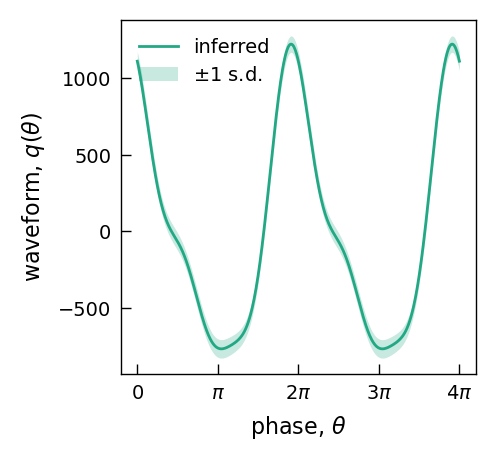

In [33]:

# fixed axis geometry
ax_h = 4.5 * cm
ax_w = 4.5 * cm

left = 1.5 * cm
bottom = 1.5 * cm
right = 0.5 * cm
top = 0.5 * cm

fig_w = left + ax_w + right
fig_h = bottom + ax_h + top

fig = plt.figure(figsize=(fig_w, fig_h))

ax = fig.add_axes([
    left / fig_w,
    bottom / fig_h,
    ax_w / fig_w,
    ax_h / fig_h
])

# Plot the data
ax.plot(
    theta_fit,
    q_mean,
    lw=1,
    color=cmap(0.6),
    label="inferred",
)
ax.fill_between(
    theta_fit,
    q_lo,
    q_hi,
    color=cmap(0.6),
    alpha=0.25,
    linewidth=0,
    label=r"$\pm 1$ s.d.",
)


# Set axis labels with font size 9 pt
ax.set_xlabel(r'phase, $\theta$', fontsize=8)
ax.set_ylabel(r'waveform, $q(\theta)$', fontsize=8);

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_xticks([0, np.pi, 2*np.pi, 3*np.pi, 4*np.pi])
ax.set_xticklabels([
    r"$0$",
    r"$\pi$",
    r"$2\pi$",
    r"$3\pi$",
    r"$4\pi$",
])

ax.legend(frameon=False, fontsize=7, loc=2)

# Set the x-axis limits from 0 to 2000
# ax.set_xlim(0, 4*np.pi)
# ax.set_ylim(0, 2.5)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
    
plt.savefig('plots/Hippocampal_Waveform.pdf')

### Time scale

relaxation time = 0.73929


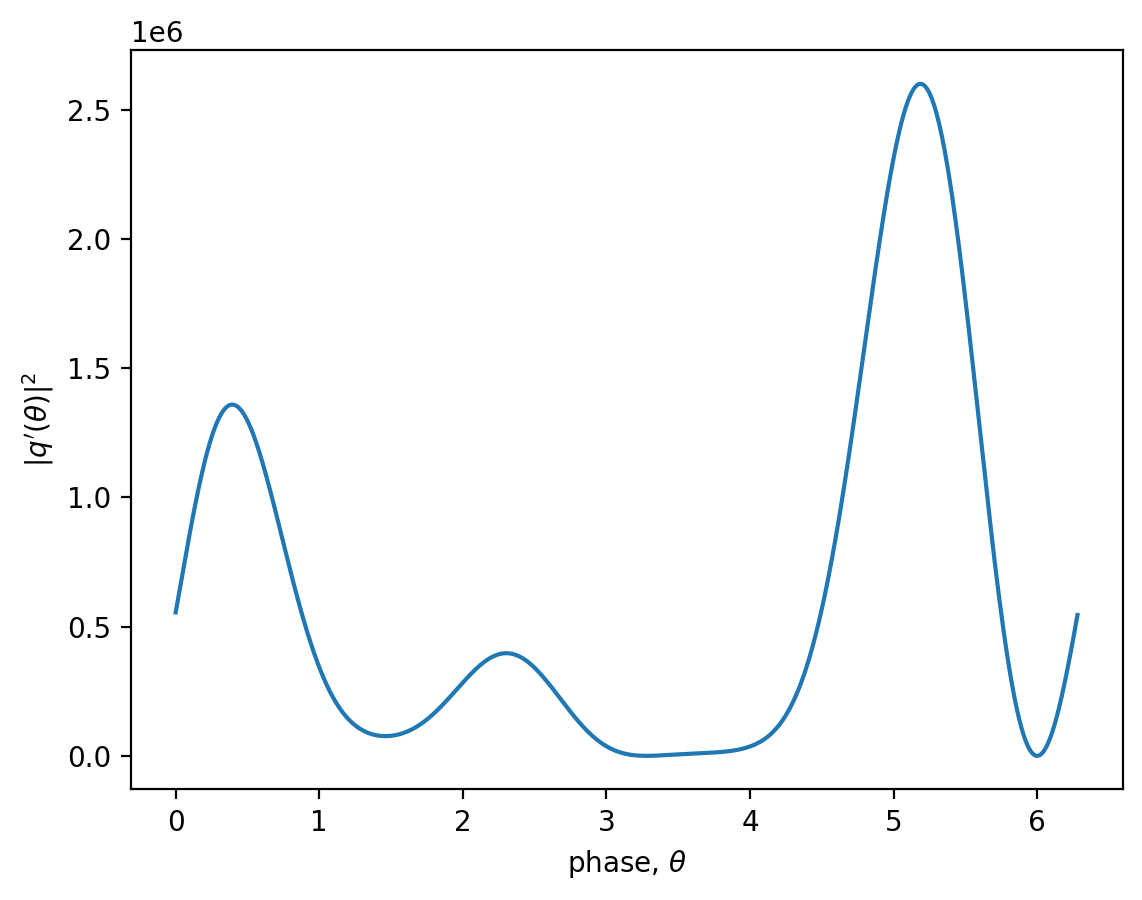

In [34]:
A = lambda_map_jax[3]
B = lambda_map_jax[4]

omega_map = lambda_map_jax[0]
Dtheta_map = np.exp(lambda_map_jax[1])
R_eff = np.exp(lambda_map_jax[2])

theta_grid = np.linspace(0, 2*np.pi, 2000, endpoint=False)

q = HP.q_fourier(theta_grid, A, B)
dq = HP.q_fourier_prime(theta_grid, A, B)

dq2_mean = np.mean(dq**2)
R_phase_step = R_eff / dq2_mean
tau_phase_step = R_phase_step / Dtheta_map

print(f'relaxation time = {tau_phase_step:.5f}')

plt.plot(theta_grid, dq**2)

plt.xlabel(r"phase, $\theta$")
plt.ylabel(r"$|q'(\theta)|^2$");

#  Estimating latent phase, $p(\theta_{1:N} \mid y_{1:N}, \lambda)$

## Global Phase Filter

In [35]:
%%time
param = lambda_map_jax

phase_filter = HP.global_phase_filter(
    param,
    data_reg,
    state_priors,
    n_theta=n_theta,
    transition="spectral", # spectral or sampled
    validate=True,
)

phase_smoother = HP.global_phase_smoother(
    phase_filter,
    validate=True,
)

theta_grid = phase_smoother["theta_grid"]
gamma = phase_smoother["gamma"]   # shape (N, n_theta)

CPU times: user 207 ms, sys: 7 ms, total: 214 ms
Wall time: 254 ms


We can compute $\log p(y_{1:N}\mid \lambda)$ from the Kalman filter.

In [36]:
nlml = HP.neg_log_marginal_likelihood(param, data_reg, state_priors, n_theta=n_theta)
print(f'Negative log marginal likelihood: {nlml:.5}')

Negative log marginal likelihood: 3.3632e+04


### Inferred phase

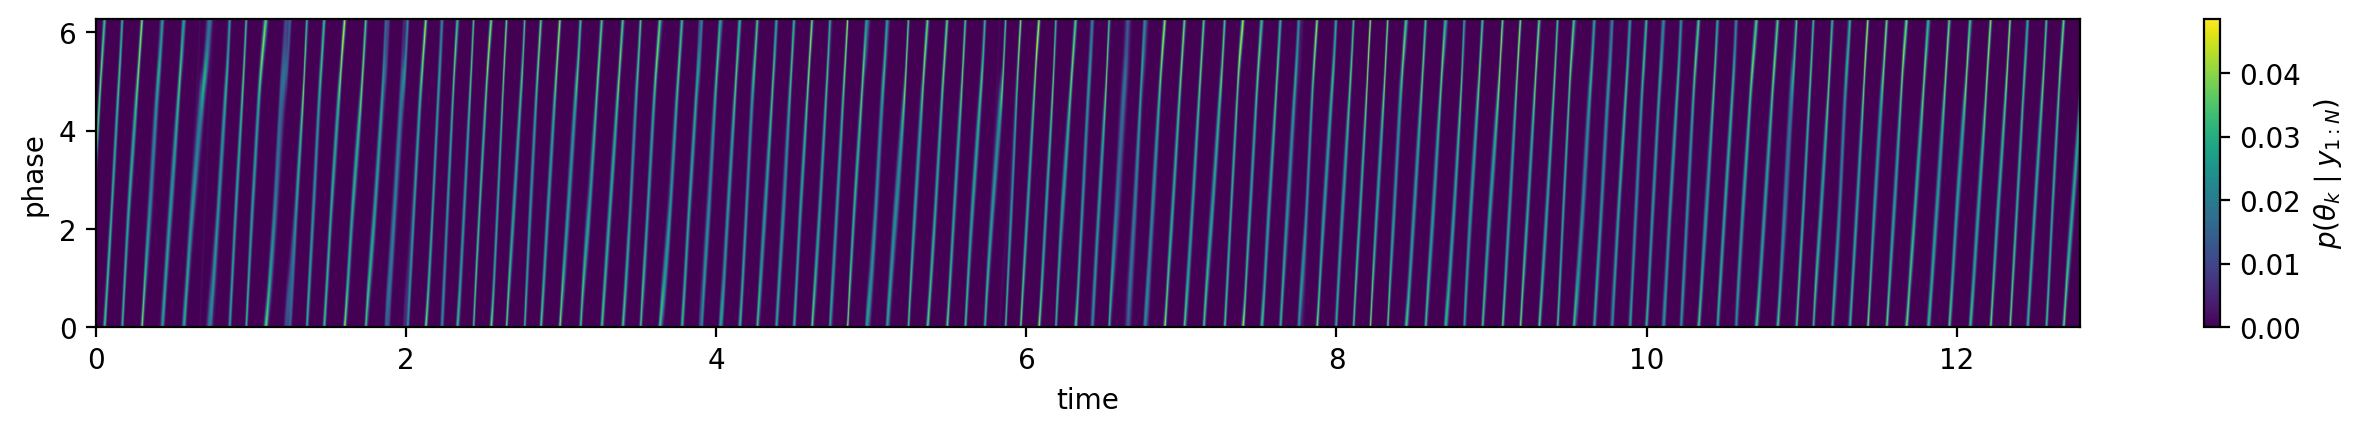

In [37]:
fig, ax = plt.subplots(figsize=(16, 2))

im = ax.imshow(
    # np.log(gamma.T+1e-10),
    gamma.T,
    origin="lower",
    aspect="auto",
    extent=[tk[0], tk[-1], theta_grid[0], theta_grid[-1]],
)

ax.set_xlabel("time")
ax.set_ylabel("phase")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label(r"$p(\theta_k \mid y_{1:N})$")

Mean and variance of the phase.

In [38]:
# gamma shape: (N, n_theta)
# theta_grid shape: (n_theta,)
z = gamma @ np.exp(1j * theta_grid)   # E[e^{i theta_k} | y]

theta_mean_wrapped = np.angle(z)      # in [-pi, pi)
theta_mean = np.unwrap(theta_mean_wrapped)

Rbar = np.abs(z)                      # mean resultant length

# Circular standard deviation
theta_std = np.sqrt(-2.0 * np.log(np.clip(Rbar, 1e-15, 1.0)))

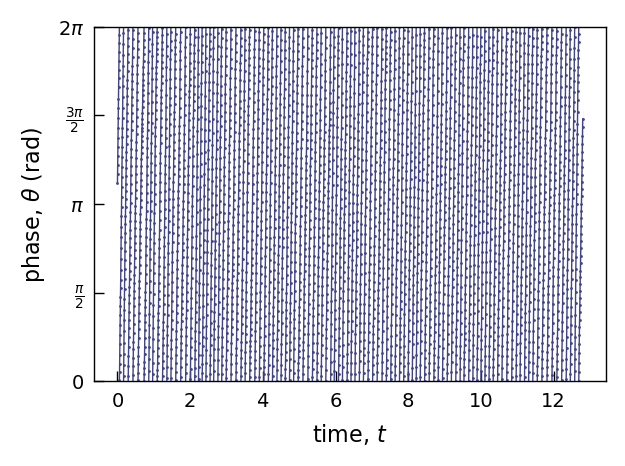

In [39]:
scale = 1

# Desired axes dimensions in centimeters
axes_width_cm = 6.5 * scale
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm * cm    # ~2.362 in
axes_height_in = axes_height_cm * cm  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, np.mod(theta_mean, 2*np.pi), '.', ms=2, mew=0, color=cmap(0.2))

ymin = -0.5 * np.pi
ymax =  2.5 * np.pi

theta_upper = theta_mean + theta_std
theta_lower = theta_mean - theta_std

for shift in 2*np.pi * np.arange(-500, 5):
    y_mean = theta_mean + shift
    y_lo = theta_lower + shift
    y_hi = theta_upper + shift

    visible = (y_hi >= ymin) & (y_lo <= ymax)

    ax.plot(
        tk[visible],
        y_mean[visible],
        "-",
        lw=0.5,
        color=cmap(0.2),
    )

    ax.fill_between(
        tk[visible],
        y_lo[visible],
        y_hi[visible],
        color=cmap(0.2),
        alpha=0.2,
        lw=0,
    )
    
# Set axis labels with font size 8 pt
ax.set_xlabel(r'time, $t$', fontsize=8)
ax.set_ylabel(r'phase, $\theta$ (rad)', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

ax.set_yticks([0,
               np.pi/2,
               np.pi,
               3*np.pi/2,
               2*np.pi])

ax.set_yticklabels([r'$0$',
                    r'$\frac{\pi}{2}$',
                    r'$\pi$',
                    r'$\frac{3\pi}{2}$',
                    r'$2\pi$'])

# ax.set_xlim(tk[0], tk[-1])
# ax.set_xlim(15, 20)
ax.set_ylim(0, 2*np.pi)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalTrace_Inferred.pdf')

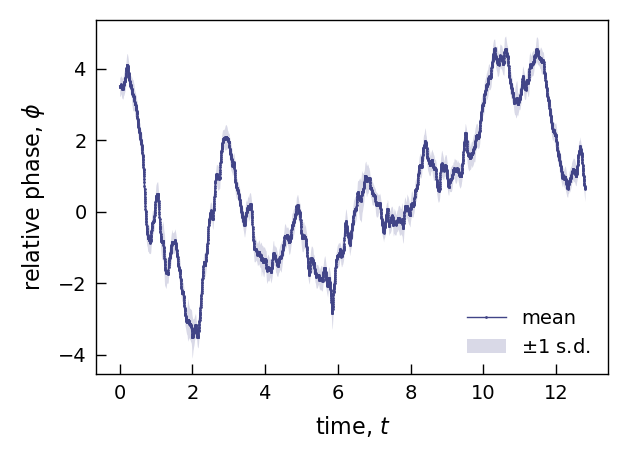

In [41]:
# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

shift = np.floor( (theta_mean[0] - param[0]*tk[0]) / (2*np.pi) ) * 2*np.pi
ax.plot(tk, theta_mean - param[0]*tk - shift, '.-', ms=2, mew=0, lw=0.5, 
        color=cmap(0.2), label=r'mean');

phi_upper = theta_mean - param[0]*tk - shift + theta_std
phi_lower = theta_mean - param[0]*tk - shift - theta_std
ax.fill_between(tk, phi_upper, phi_lower, color=cmap(0.2), alpha=0.2, lw=0,
               label=r'$\pm 1$ s.d.');

# Set axis labels with font size 9 pt
ax.set_xlabel(r'time, $t$', fontsize=8)
ax.set_ylabel(r'relative phase, $\phi$', fontsize=8)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# ax.set_yticks([np.pi/2,
#                # 3*np.pi/4,
#                np.pi,
#                # 5*np.pi/4,
#                3*np.pi/2])

# ax.set_yticklabels([r'$\frac{\pi}{2}$',
#                     # r'$\frac{3\pi}{4}$',
#                     r'$\pi$',
#                     # r'$\frac{5\pi}{4}$',
                    # r'$\frac{3\pi}{2}$'])

# ax.set_xlim(0, N*dt)
# ax.set_ylim(1*np.pi/4, 7*np.pi/4)
plt.legend(frameon=False, fontsize=7, loc=4)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalTrace_Phi.pdf')

### Posterior predictive distribution

In [42]:
R = np.exp(param[2])

# waveform on phase grid
q_grid = phase_filter["q_grid"]   # or q_fourier(theta_grid, A, B)

# posterior predictive mean
y_mean = gamma @ q_grid

# posterior predictive variance:
# Var(y_rep | data) = R + Var[q(theta_k) | data]
q2_mean = gamma @ (q_grid**2)
y_var = R + q2_mean - y_mean**2
y_std = np.sqrt(np.maximum(y_var, 0.0))

# +/- one SD 
lo = y_mean - y_std
hi = y_mean + y_std

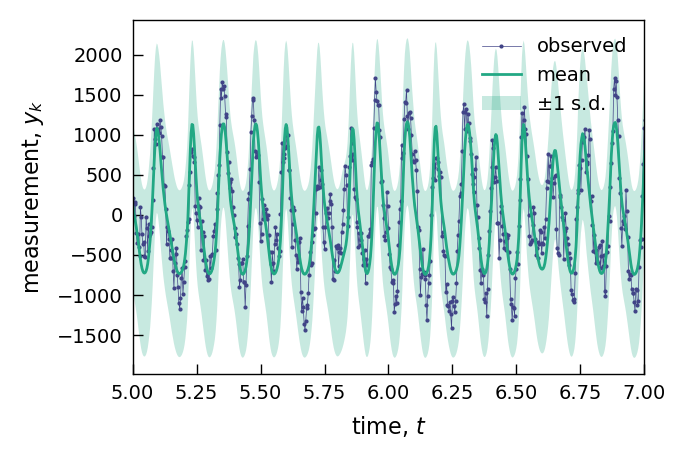

In [44]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot the data
ax.plot(tk, yk, '.-', lw=0.25, mew=0, ms=3, color=cmap(0.2), label='observed')
ax.plot(tk, y_mean, color=cmap(0.6), lw=1, label="mean")
ax.fill_between(tk, lo, hi, color=cmap(0.6), lw=0, alpha=0.25, label=r"$\pm 1$ s.d.")

# Set axis labels with font size 8 pt
ax.set_xlabel(r'time, $t$', fontsize=8)
ax.set_ylabel(r'measurement, $y_k$', fontsize=8)

# Create legend (frame turned off)
ax.legend(frameon=False, fontsize=7)

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the x-axis limits from 0 to 2000
# ax.set_xlim(tk[0], tk[-1] - 0.80*(tk[-1]-tk[0]))
# ax.set_ylim(0, 3.5)
ax.set_xlim(5, 7)

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/Hippocampal_PosteriorPredictive.pdf')

### Residuals

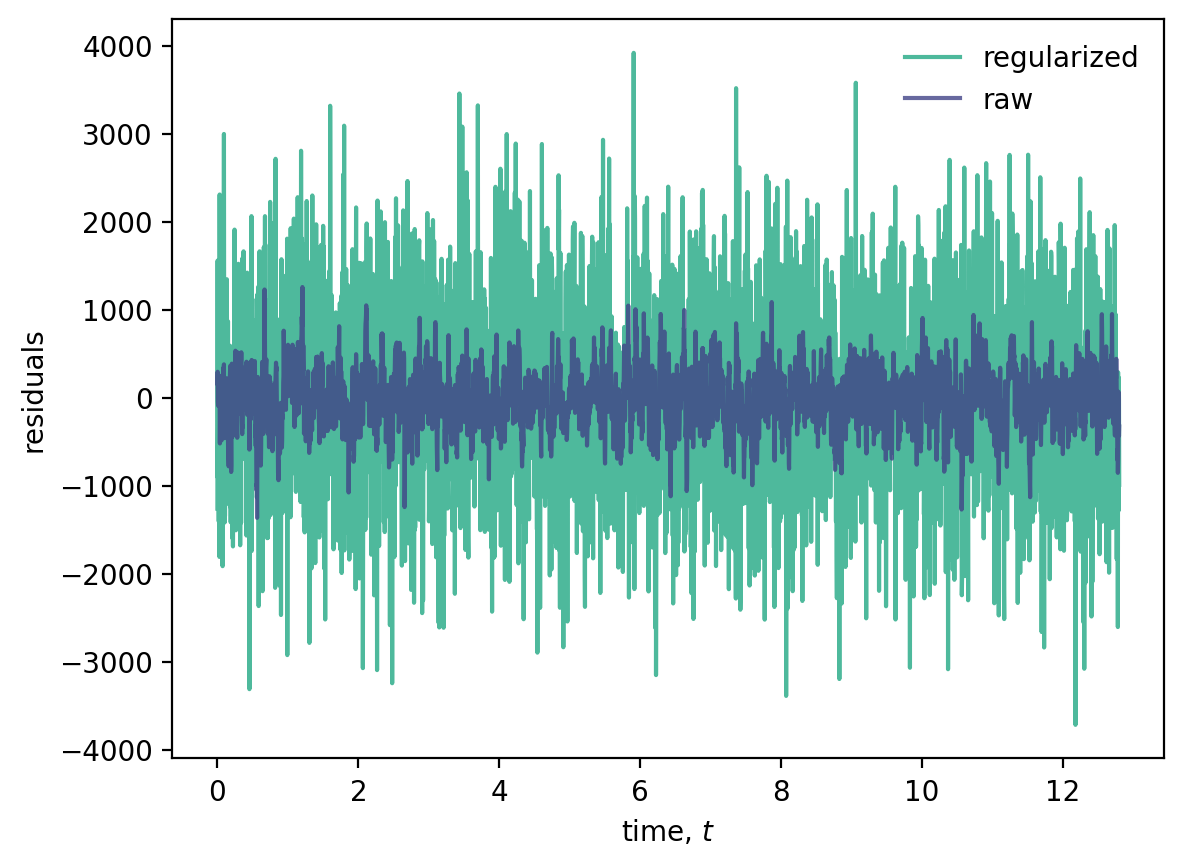

In [45]:
res = yk - y_mean
res_reg = yk_reg - y_mean

plt.plot(tk, res_reg, color=cmap(0.6), alpha=0.8, label='regularized')
plt.plot(tk, res, color=cmap(0.2), alpha=0.8, label='raw')

plt.legend(frameon=False)
plt.xlabel('time, $t$');
plt.ylabel('residuals');

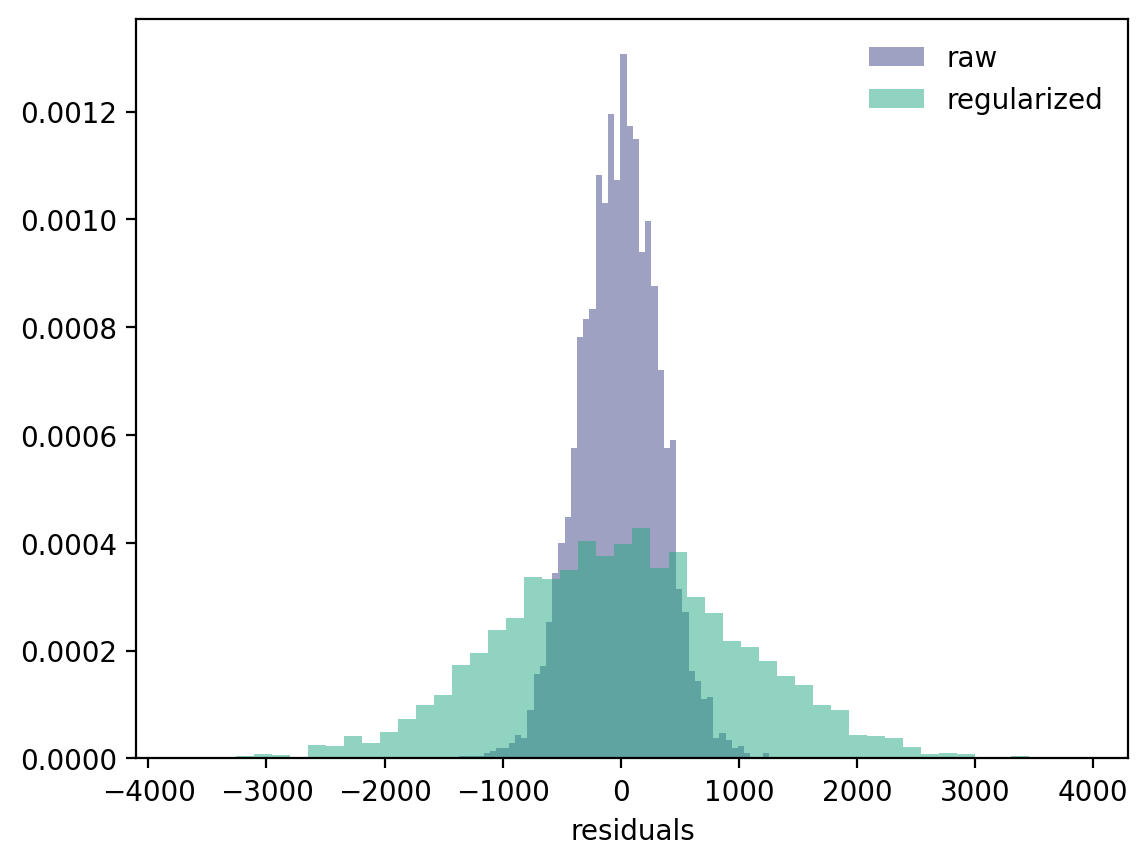

In [46]:
plt.hist(res, bins=50, color=cmap(0.2), alpha=0.5, label='raw', density=True)
plt.hist(res_reg, bins=50, color=cmap(0.6), alpha=0.5, label='regularized', density=True)
plt.legend(frameon=False)
plt.xlabel('residuals');

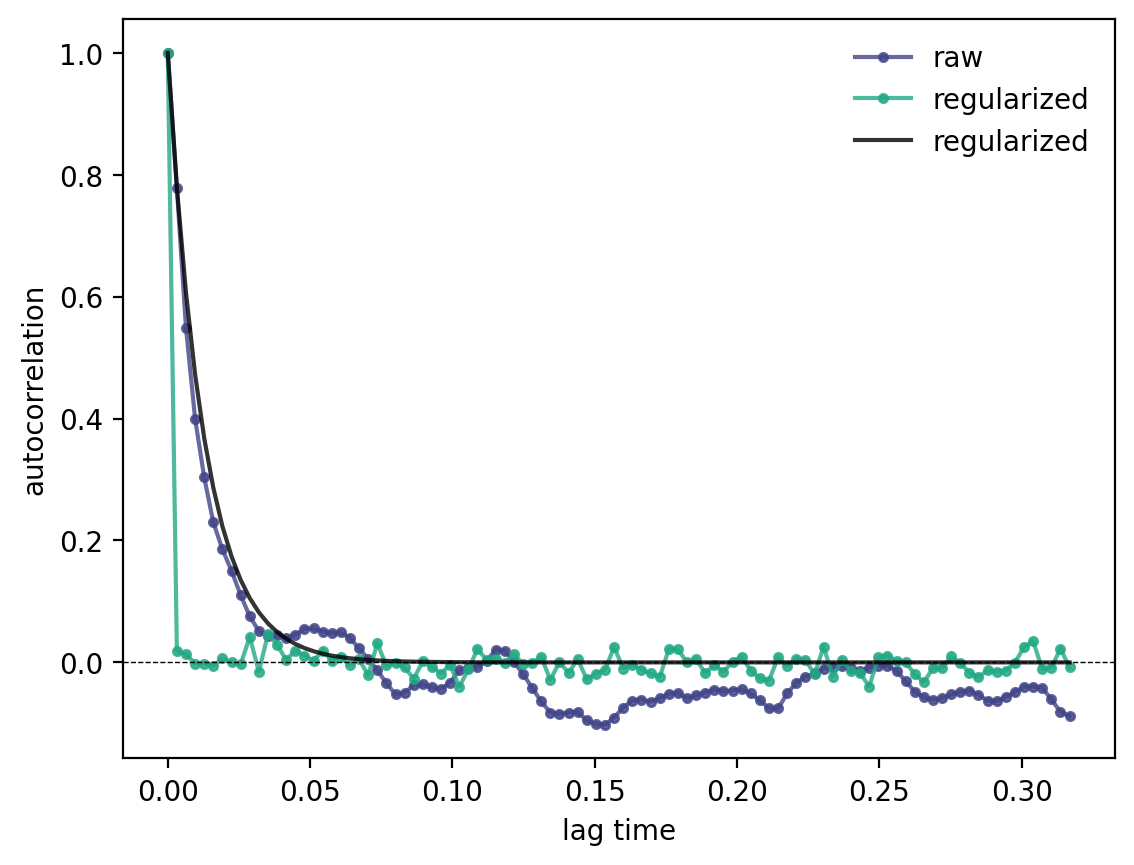

In [47]:
acf = np.correlate(res, res, mode="full")[len(res)-1:]
acf = acf / acf[0]
lags = np.arange(len(acf)) * dt

acf_reg = np.correlate(res_reg, res_reg, mode="full")[len(res_reg)-1:]
acf_reg = acf_reg / acf_reg[0]

cycles = 2
imax = 100
plt.plot(lags[:imax], acf[:imax], '.-', color=cmap(0.2), alpha=0.8, label='raw')
plt.plot(lags[:imax], acf_reg[:imax], '.-', color=cmap(0.6), alpha=0.8, label='regularized')
plt.plot(lags[:imax], np.exp(-lags[:imax]/0.0128), 'k-',alpha=0.8, label='regularized')

plt.axhline(0, color='k', lw=0.5, ls='--')

plt.legend(frameon=False, loc=1)
plt.ylabel('autocorrelation')
plt.xlabel('lag time');

## Posterior predictive check (PPC)

We assess whether the inferred latent phase dynamics are consistent with the fitted diffusing phase model. 
For each posterior parameter sample $\lambda_s=(\omega_s, \ln D_{\theta,s},\ldots)$, we generate two phase trajectories:

1. an inferred trajectory sampled from the smoothing distribution $p(\theta\mid y,\lambda_s)$, and  
2. a simulated trajectory generated directly from the phase diffusion model $p(\theta \mid \lambda_s)$

We first compare the mean-squared displacement (MSD) of the drift-subtracted phase,
$$\phi(t)=\theta(t)-\omega_s t,$$
as a function of lag time $\tau$,
$$\mathrm{MSD}(\tau)=\left\langle [\phi(t+\tau)-\phi(t)]^2\right\rangle .$$
Agreement between inferred and simulated MSDs indicates consistency at the level of the second moment and the fitted diffusivity.

Because phase-slip defects can preserve the MSD while altering the shape of the increment distribution, we also examine normalized phase increments at $\tau\approx 1/\hat{D}_\theta$,
$$
r(t,\tau)=
\frac{\phi(t+\tau)-\phi(t)}
{\sqrt{2 D_\theta\,\tau}} .
$$
For the simulated phase trajectories, $r\sim\mathcal N(0,1)$. We quantify deviations using the excess non-Gaussian parameter,
$$
\alpha_2 =
\frac{\langle r^4\rangle}
{3\langle r^2\rangle^2}
-1 .
$$
Thus the MSD PPC detects errors in the scale of phase dispersion, while the non-Gaussian PPC detects slip-induced heavy tails or other deviations from Gaussian phase increments.

### Sample parameters from $p(\lambda \mid y)$

In [48]:
n_param_samples = 50
n_phase_per_param = 2
n_samples = n_param_samples * n_phase_per_param

L = np.linalg.cholesky(H_direct)
z = rng.standard_normal((n_param_samples, len(x_jax)))

dx = solve_triangular(
    L.T,
    z.T,
    lower=False
).T

x_samples = x_jax + dx

### Inferred phase trajectories

Serial version.

In [49]:
%%time 

theta_inf_samples = np.empty((N, n_param_samples, n_phase_per_param))
phi_inf_samples   = np.empty((N, n_param_samples, n_phase_per_param))

for s in range(n_param_samples):

    # infer phase distribution
    phase_filter = HP.global_phase_filter(
        HP.unpack_param(x_samples[s, :], M),
        data_reg,
        state_priors,
        n_theta=n_theta,
        transition="spectral",
        validate=False,
    )

    # sample multiple phase trajectories
    theta_s, _ = HP.sample_phase_trajectories_global(
        phase_filter,
        n_samples=n_phase_per_param,
        rng=rng,
    )

    theta_inf_samples[:, s, :] = theta_s.T

    phi_inf_samples[:, s, :] = (
        theta_s.T - x_samples[s, 0] * tk[:, None]
    )

phi_inf_samples = np.unwrap(phi_inf_samples, axis=0)
phi_inf_samples = phi_inf_samples.reshape(N, n_samples)

CPU times: user 9.48 s, sys: 142 ms, total: 9.63 s
Wall time: 9.72 s


Parallel version.

In [50]:
%%time 

seeds = rng.integers(0, 2**32 - 1, size=n_param_samples)

def infer_one_param_sample(s):
    # local RNG for reproducibility / no shared RNG state
    rng_s = np.random.default_rng(seeds[s])

    phase_filter = HP.global_phase_filter(
        HP.unpack_param(x_samples[s, :], M),
        data_reg,
        state_priors,
        n_theta=n_theta,
        transition="spectral",
        validate=False,
    )

    theta_s, _ = HP.sample_phase_trajectories_global(
        phase_filter,
        n_samples=n_phase_per_param,
        rng=rng_s,
    )

    theta_s = theta_s.T  # (N, n_phase_per_param)

    phi_s = theta_s - x_samples[s, 0] * tk[:, None]

    return theta_s, phi_s


out = Parallel(n_jobs=-1)(
    delayed(infer_one_param_sample)(s)
    for s in range(n_param_samples)
)

theta_inf_samples = np.empty((N, n_param_samples, n_phase_per_param))
phi_inf_samples   = np.empty((N, n_param_samples, n_phase_per_param))

for s, (theta_s, phi_s) in enumerate(out):
    theta_inf_samples[:, s, :] = theta_s
    phi_inf_samples[:, s, :] = phi_s

phi_inf_samples = np.unwrap(phi_inf_samples, axis=0)
phi_inf_samples = phi_inf_samples.reshape(N, n_samples)

CPU times: user 120 ms, sys: 106 ms, total: 226 ms
Wall time: 3.38 s


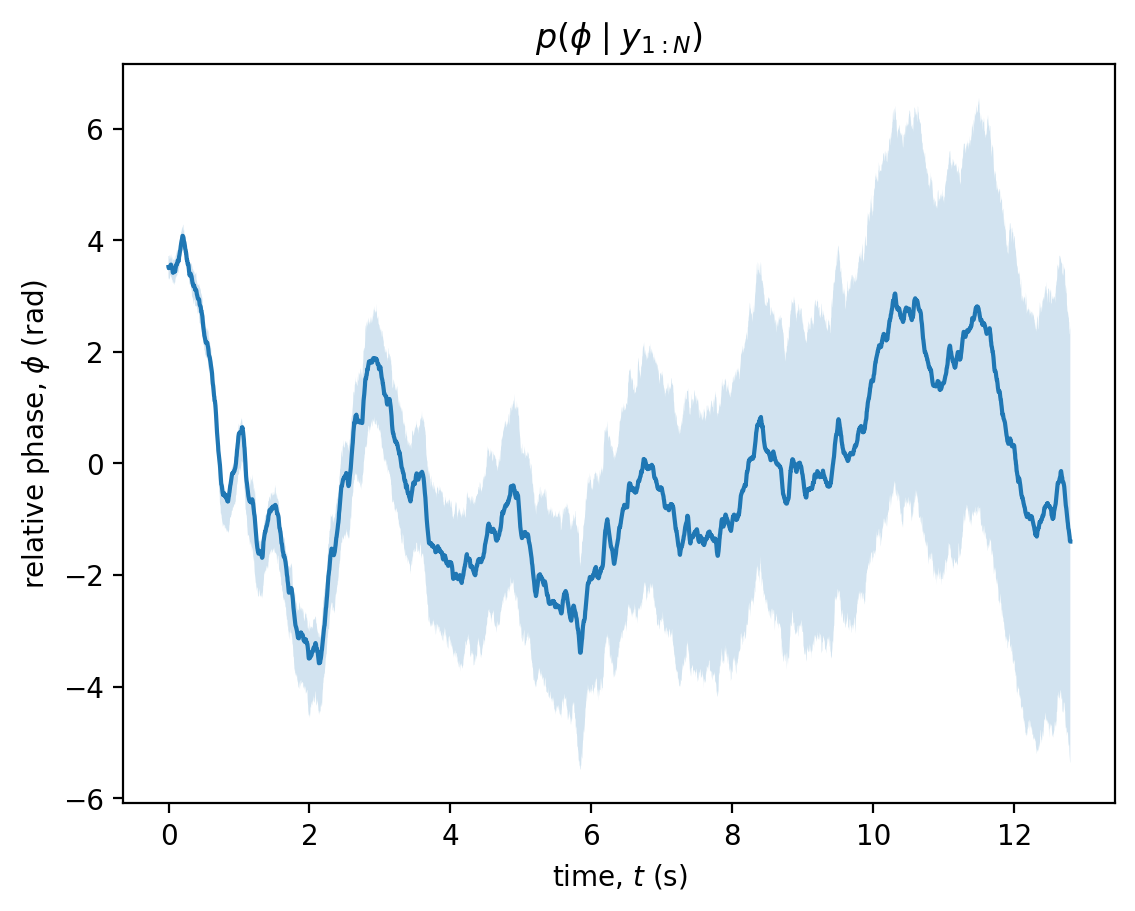

In [52]:
phi_inf_mean = np.mean(phi_inf_samples, axis=1)
phi_inf_lo = np.percentile(phi_inf_samples, 25, axis=1)
phi_inf_hi = np.percentile(phi_inf_samples, 75, axis=1)

plt.plot(tk, phi_inf_mean)
plt.fill_between(tk, phi_inf_lo, phi_inf_hi, alpha=0.2)

plt.xlabel('time, $t$ (s)')
plt.ylabel(r'relative phase, $\phi$ (rad)')
plt.title(r'$p(\phi \mid y_{1:N})$');

In [137]:
# np.savez(
#     "phi_inf_data_good.npz",
#     tk=tk,
#     phi_inf_mean=phi_inf_mean,
#     phi_inf_lo=phi_inf_lo,
#     phi_inf_hi=phi_inf_hi,
# )

# np.savez(
#     "phi_inf_data_bad.npz",
#     tk=tk,
#     phi_inf_mean=phi_inf_mean,
#     phi_inf_lo=phi_inf_lo,
#     phi_inf_hi=phi_inf_hi,
# )

### Simulated phase trajectories

In [53]:
def simulate_phase_trajectory(omega, Dtheta, N, dt, rng, theta0=0.0):
    dtheta = omega * dt + np.sqrt(2 * Dtheta * dt) * rng.standard_normal(N - 1)
    theta = np.empty(N)
    theta[0] = theta0
    theta[1:] = theta0 + np.cumsum(dtheta)
    return theta

In [54]:
theta_sim_samples = np.empty((N, n_param_samples, n_phase_per_param))
phi_sim_samples   = np.empty((N, n_param_samples, n_phase_per_param))

for s in range(n_param_samples):

    omega_s = x_samples[s, 0]
    Dtheta_s = np.exp(x_samples[s, 1])

    for p in range(n_phase_per_param):

        theta_sim_samples[:, s, p] = simulate_phase_trajectory(
            omega_s,
            Dtheta_s,
            len(tk),
            dt,
            rng,
        )

        phi_sim_samples[:, s, p] = (
            theta_sim_samples[:, s, p]
            - omega_s * tk
        )

phi_sim_samples = np.unwrap(phi_sim_samples, axis=0)
phi_sim_samples = phi_sim_samples.reshape(N, n_samples)

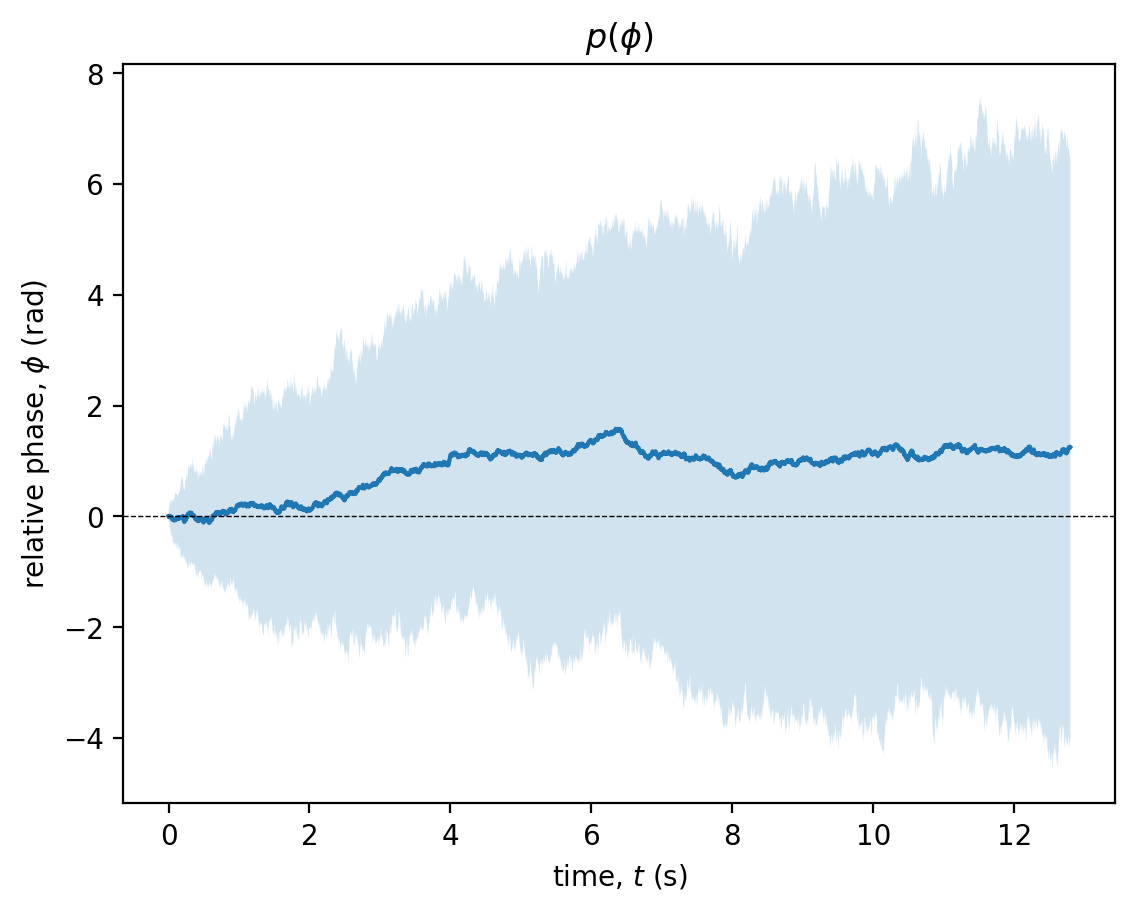

In [55]:
phi_sim_mean = np.mean(phi_sim_samples, axis=1)
phi_sim_low = np.percentile(phi_sim_samples, 25, axis=1)
phi_sim_high = np.percentile(phi_sim_samples, 75, axis=1)

plt.plot(tk, phi_sim_mean)
plt.fill_between(tk, phi_sim_low, phi_sim_high, alpha=0.2)
plt.axhline(y=0, color='k', lw=0.5, ls='--')

plt.xlabel('time, $t$ (s)')
plt.ylabel(r'relative phase, $\phi$ (rad)')
plt.title(r'$p(\phi)$');

### MSD vs. time with uncertainty

In [56]:
lags = np.unique(np.rint(np.logspace(0, np.log10(int(N/4)), 50))).astype(int)
taus = lags * dt

msd_sim = np.empty((len(lags), n_samples))
msd_inf = np.empty((len(lags), n_samples))

for s in range(n_samples):
    for a, lag in enumerate(lags):
            tau = lag * dt
            dphi = phi_sim_samples[lag:,s] - phi_sim_samples[:-lag,s]
            msd_sim[a,s] = np.mean(dphi**2)

            dphi = phi_inf_samples[lag:,s] - phi_inf_samples[:-lag,s]
            msd_inf[a,s] = np.mean(dphi**2)

In [57]:
msd_inf_mean = np.mean(msd_inf, axis=1)
msd_inf_lo = np.percentile(msd_inf, 25, axis=1)
msd_inf_hi = np.percentile(msd_inf, 75, axis=1)

msd_sim_mean = np.mean(msd_sim, axis=1)
msd_sim_lo = np.percentile(msd_sim, 25, axis=1)
msd_sim_hi = np.percentile(msd_sim, 75, axis=1)

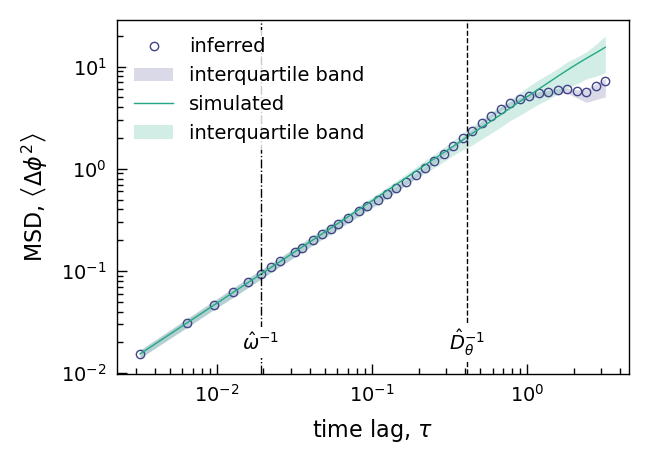

In [60]:
# Desired axes dimensions in centimeters
axes_width_cm = 6.5
axes_height_cm = 4.5

# Convert centimeters to inches (1 inch = 2.54 cm)
axes_width_in = axes_width_cm / 2.54    # ~2.362 in
axes_height_in = axes_height_cm / 2.54  # ~1.772 in

# Define margins for labels/ticks in inches (adjust as needed)
left_margin = 0.6
right_margin = 0.2
bottom_margin = 0.6
top_margin = 0.2

# Overall figure size in inches: axes area plus margins
fig_width = axes_width_in + left_margin + right_margin
fig_height = axes_height_in + bottom_margin + top_margin

# Create figure with computed size
fig = plt.figure(figsize=(fig_width, fig_height))

# Calculate normalized (0-1) coordinates for the axes
left_norm = left_margin / fig_width
bottom_norm = bottom_margin / fig_height
axes_width_norm = axes_width_in / fig_width
axes_height_norm = axes_height_in / fig_height

# Add axes with the computed position; this sets the axes frame to be exactly 6 cm by 4.5 cm.
ax = fig.add_axes([left_norm, bottom_norm, axes_width_norm, axes_height_norm])

# Plot inferred data
plt.loglog(taus, msd_inf_mean, 'o', mew=0.5, ms=3, mec=cmap(0.2), mfc='None', alpha=1, 
           label=r'inferred')
plt.fill_between(taus, msd_inf_lo, msd_inf_hi, lw=0, color=cmap(0.2), alpha=0.2, label="interquartile band")

# Plot simulated
plt.loglog(taus, msd_sim_mean, '-', lw=0.5, color=cmap(0.6), alpha=1, 
           label=r'simulated')
plt.fill_between(taus, msd_sim_lo, msd_sim_hi, lw=0, color=cmap(0.6), alpha=0.2, label="interquartile band")

ax.axvline(x=1/Dtheta, ls='--', lw=0.5, color='k')
ax.text(
    1/Dtheta,
    0.02,                       # y-position in data coordinates
    r'$\hat{D}_\theta^{-1}$',
    fontsize=7,
    ha='center',
    va='center',
    bbox=dict(
        facecolor='white',
        alpha=1,
        edgecolor='none',
        pad=1.5
    )
)

ax.axvline(x=1/omega, ls='-.', lw=0.5, color='k')
ax.text(
    1/omega,
    0.02,                       # y-position in data coordinates
    r'$\hat{\omega}^{-1}$',
    fontsize=7,
    ha='center',
    va='center',
    bbox=dict(
        facecolor='white',
        alpha=1,
        edgecolor='none',
        pad=1.5
    )
)
    
# Set axis labels with font size 8 pt
ax.set_xlabel(r'time lag, $\tau$', fontsize=8)
ax.set_ylabel(r"MSD, $\left\langle \Delta\phi^2 \right\rangle$",  fontsize=8)
# ax.set_xlim(0.01,10)

# Create legend (frame turned off)
ax.legend(frameon=True, fontsize=7, loc=2,
          facecolor='white',
          framealpha=0.8,   # transparency
          edgecolor='none',  # no border
         )

# Set tick label fonts to 7 pt, tick mark widths to 0.5 pt, and ticks pointing inward
ax.tick_params(axis='both', which='major', labelsize=7, width=0.5, direction='in')
ax.tick_params(axis='both', which='minor', labelsize=7, width=0.5, direction='in')

# Set the width of the frame (all spines) to 0.5 pt
for spine in ax.spines.values():
    spine.set_linewidth(0.5)

plt.savefig('plots/HippocampalMSD.pdf')

In [61]:
# np.savez(
#     "msd_data_good.npz",
#     taus=taus,
#     msd_inf_mean=msd_inf_mean,
#     msd_inf_lo=msd_inf_lo,
#     msd_inf_hi=msd_inf_hi,
#     msd_sim_mean=msd_sim_mean,
#     msd_sim_lo=msd_sim_lo,
#     msd_sim_hi=msd_sim_hi,
# )

# np.savez(
#     "msd_data_bad.npz",
#     taus=taus,
#     msd_inf_mean=msd_inf_mean,
#     msd_inf_lo=msd_inf_lo,
#     msd_inf_hi=msd_inf_hi,
#     msd_sim_mean=msd_sim_mean,
#     msd_sim_lo=msd_sim_lo,
#     msd_sim_hi=msd_sim_hi,
# )

### MSD for $\tau = 1/\hat{D}_\theta$

In [62]:
tau_msd = 1/ Dtheta 
idx_msd = np.round(np.interp(tau_msd, taus, np.arange(len(taus)))).astype(int)
lag_msd = lags[idx_msd]
tau_msd = taus[idx_msd]

msd_sim_samples =  msd_sim[idx_msd,:]
msd_inf_samples =  msd_inf[idx_msd,:]

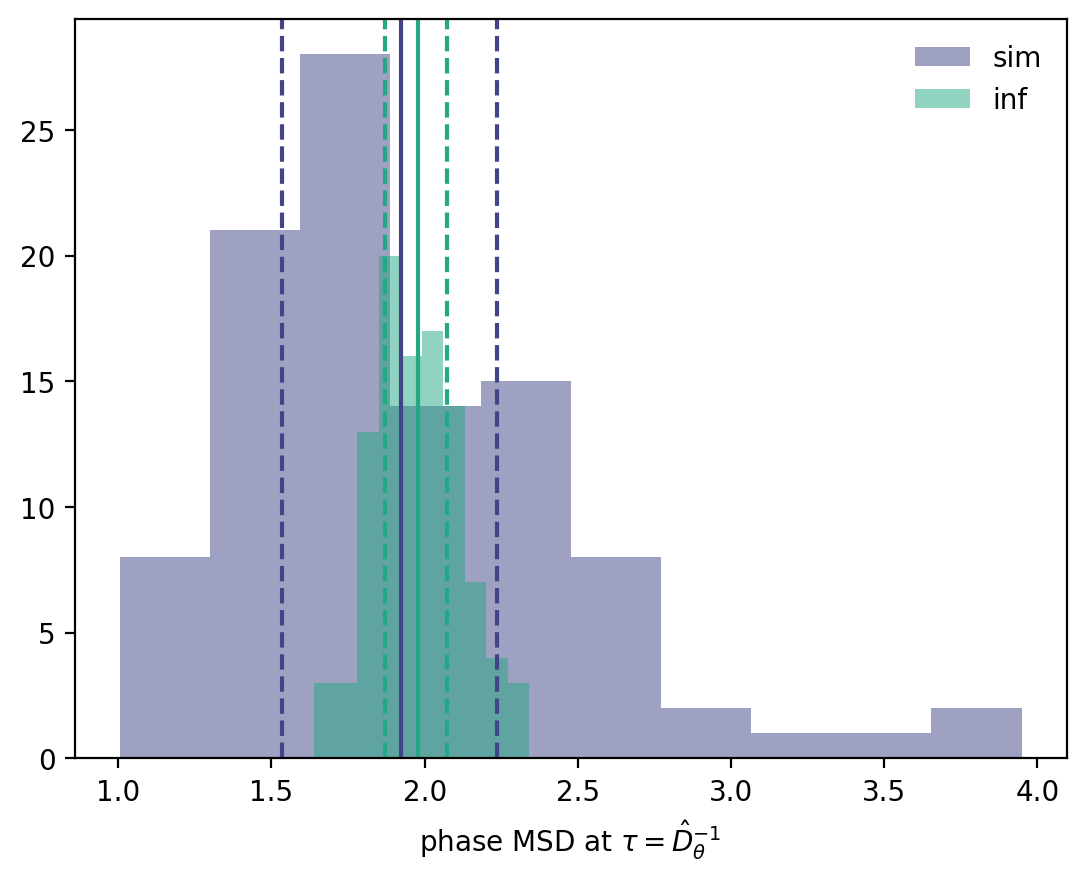

In [63]:
plt.hist(msd_sim_samples, bins=10, color=cmap(0.2), label='sim', alpha=0.5);
plt.axvline(x=msd_sim_mean[idx_msd], color=cmap(0.2))
plt.axvline(x=msd_sim_lo[idx_msd], color=cmap(0.2), ls='--')
plt.axvline(x=msd_sim_hi[idx_msd], color=cmap(0.2), ls='--')

plt.hist(msd_inf_samples, bins=10, color=cmap(0.6), label='inf', alpha=0.5);
plt.axvline(x=msd_inf_mean[idx_msd], color=cmap(0.6))
plt.axvline(x=msd_inf_lo[idx_msd], color=cmap(0.6), ls='--')
plt.axvline(x=msd_inf_hi[idx_msd], color=cmap(0.6), ls='--')

plt.legend(frameon=False);

plt.xlabel(r'phase MSD at $\tau=\hat{D}_\theta^{-1}$');

upper p-value =		 0.36
two-sided p-value =	 0.72


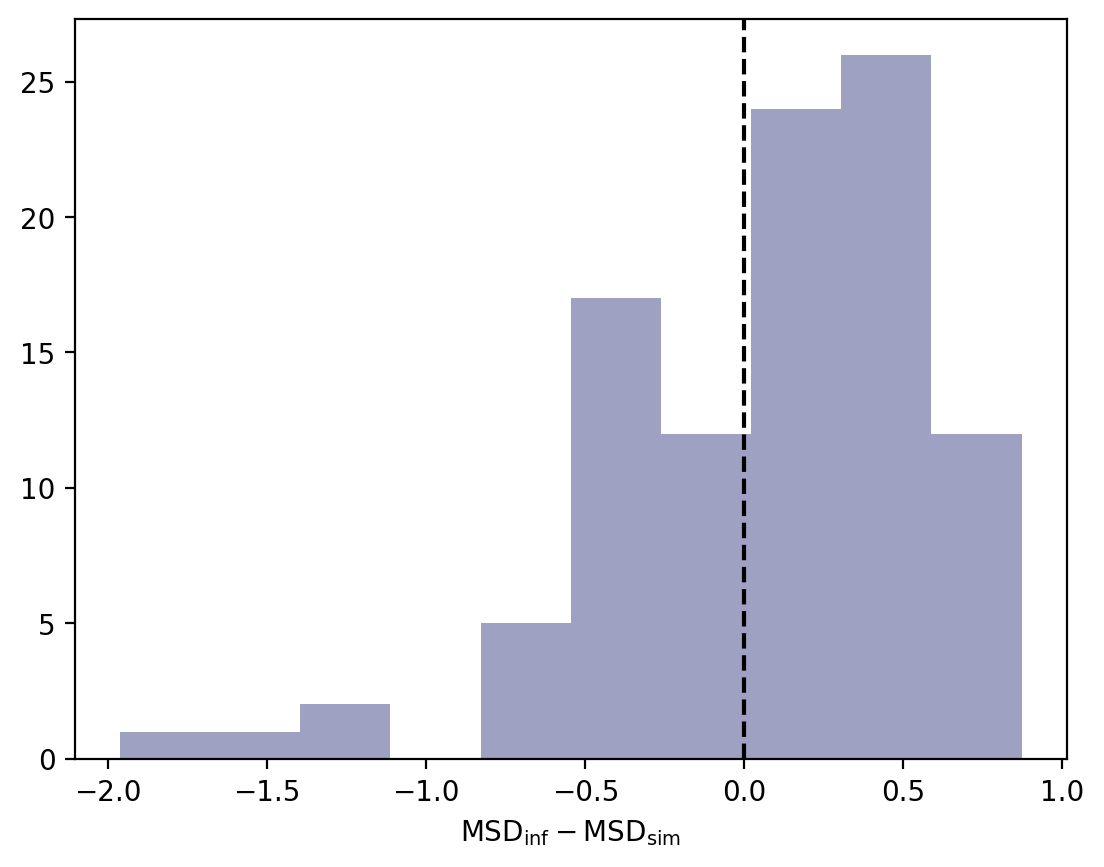

In [64]:
# PPC
delta_msd = msd_inf_samples - msd_sim_samples
p_upper = np.mean(delta_msd <= 0)   # if observed inf should be larger
p_two = 2 * min(np.mean(delta_msd >= 0), np.mean(delta_msd <= 0))

print(f'upper p-value =\t\t{p_upper:5}')
print(f'two-sided p-value =\t{p_two:5}')

plt.hist(delta_msd, bins=10, color=cmap(0.2), label='sim', alpha=0.5)
plt.axvline(x=0, color='k', ls='--')
plt.xlabel(r'$\text{MSD}_{\text{inf}} - \text{MSD}_{\text{sim}}$');

### Scaled displacement for $\tau = 1/\hat{D}_\theta$

Overlapping intervals.

In [65]:
tau_r = 1/ Dtheta 
idx_r = np.round(np.interp(tau_r, taus, np.arange(len(taus)))).astype(int)
lag_r = lags[idx_r]
tau_r = taus[idx_r]

r_sim_samples = np.empty((N-lag_r, n_samples,))
r_inf_samples = np.empty((N-lag_r, n_samples,))

for s in range(n_param_samples):
    Dtheta_s = np.exp(x_samples[s, 1])

    for n in range(n_phase_per_param):
        j = s * n_phase_per_param + n
        
        r_sim_samples[:,j] = (phi_sim_samples[lag_r:,j] - phi_sim_samples[:-lag_r,j]) / np.sqrt(2*Dtheta_s*tau_r)
        r_inf_samples[:,j] = (phi_inf_samples[lag_r:,j] - phi_inf_samples[:-lag_r,j]) / np.sqrt(2*Dtheta_s*tau_r)

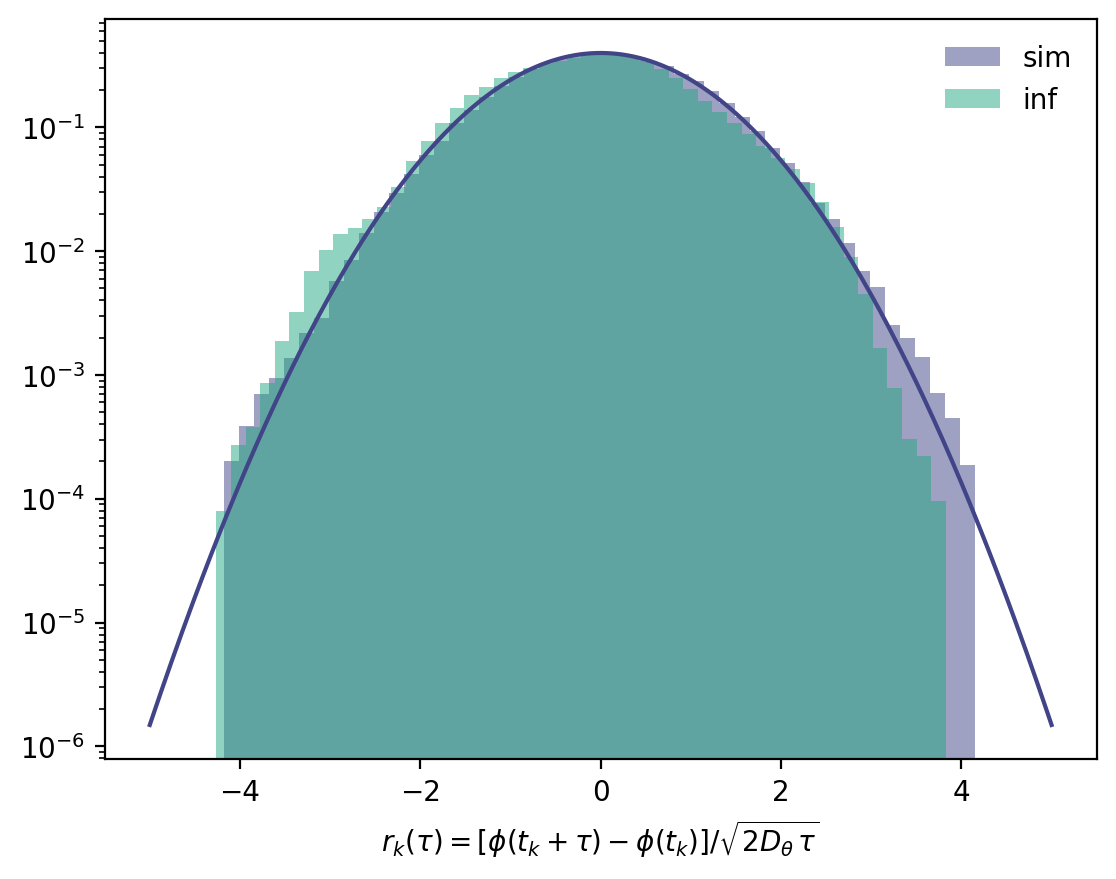

In [66]:
z = np.linspace(-5,5,500)
pdf = stats.norm.pdf(z)

plt.semilogy(z, pdf, color=cmap(0.2))
plt.hist(r_sim_samples.ravel(), bins=50, color=cmap(0.2), alpha=0.5, density=True, label='sim', )
plt.hist(r_inf_samples.ravel(), bins=50, color=cmap(0.6), alpha=0.5, density=True, label='inf')
plt.legend(frameon=False)
plt.xlabel(r'$r_k(\tau)=[\phi(t_k+\tau)-\phi(t_k)] /  \sqrt{2 D_\theta\,\tau}$');

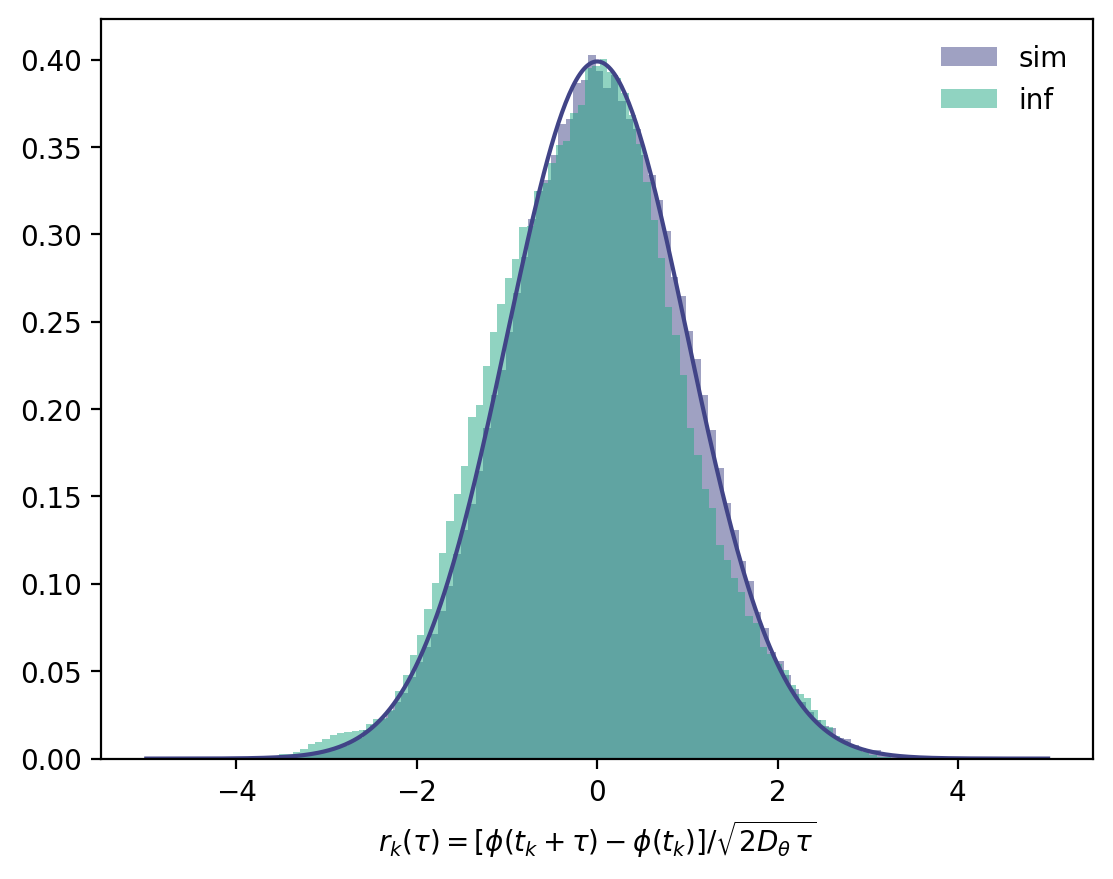

In [67]:
z = np.linspace(-5,5,500)
pdf = stats.norm.pdf(z)

plt.plot(z, pdf, color=cmap(0.2))

# s = 61
# plt.hist(r_sim_samples[:,s], bins=20, color=cmap(0.2), alpha=0.5, density=True, label='sim', )
# plt.hist(r_inf_samples[:,s], bins=20, color=cmap(0.6), alpha=0.5, density=True, label='inf')

plt.hist(r_sim_samples.ravel(), bins=100, color=cmap(0.2), alpha=0.5, density=True, label='sim', )
plt.hist(r_inf_samples.ravel(), bins=100, color=cmap(0.6), alpha=0.5, density=True, label='inf')

plt.legend(frameon=False)
plt.xlabel(r'$r_k(\tau)=[\phi(t_k+\tau)-\phi(t_k)] /  \sqrt{2 D_\theta\,\tau}$');

In [68]:
# np.savez(
#     "r_inf_samples_good.npz",
#     r_inf_samples=r_inf_samples.ravel(),
# )

# np.savez(
#     "r_inf_samples_bad.npz",
#     r_inf_samples=r_inf_samples.ravel(),
# )

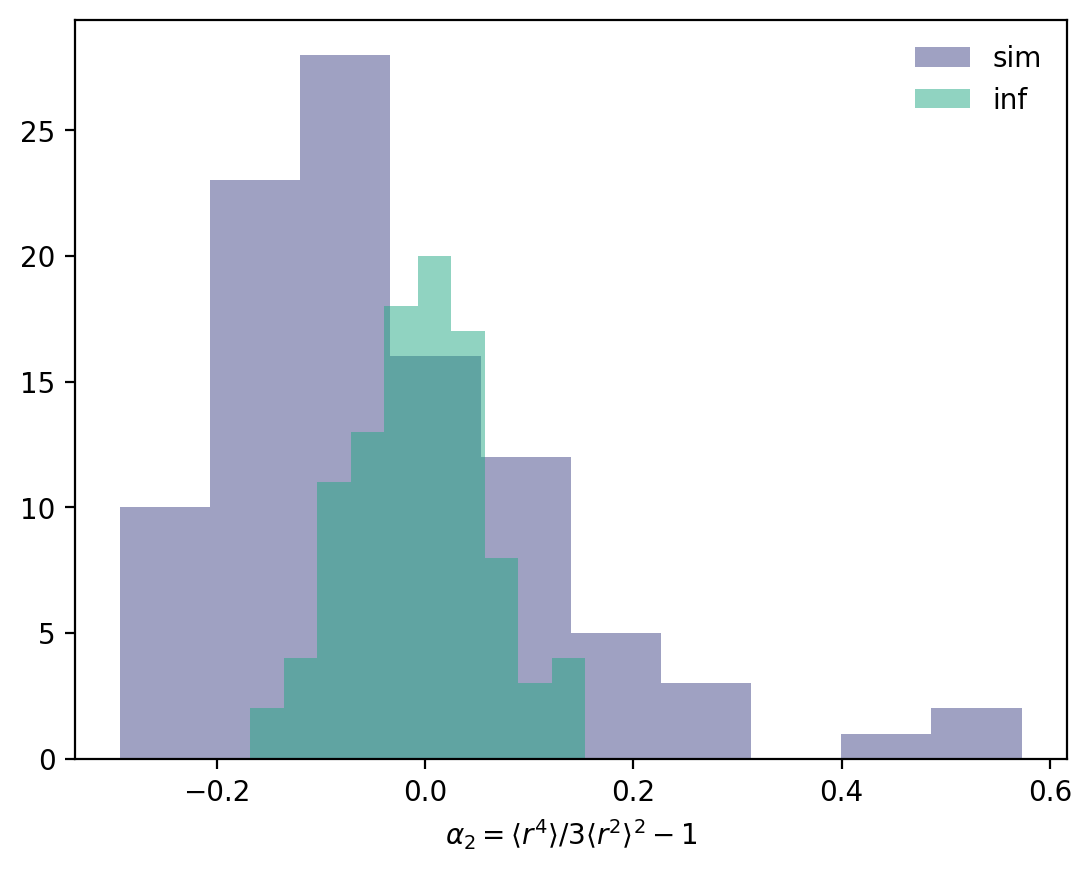

In [69]:
nongaussian_inf = np.mean(r_inf_samples**4, axis=0) / (3*np.mean(r_inf_samples**2, axis=0)**2) - 1
nongaussian_sim = np.mean(r_sim_samples**4, axis=0) / (3*np.mean(r_sim_samples**2, axis=0)**2) - 1

plt.hist(nongaussian_sim, bins=10, label='sim', alpha=0.5, color=cmap(0.2))
plt.hist(nongaussian_inf, bins=10, label='inf', alpha=0.5, color=cmap(0.6))
plt.legend(frameon=False)

plt.xlabel(r'$\alpha_2 = \langle r^4\rangle / 3\langle r^2\rangle^2 - 1$');

upper p-value =		 0.33
two-sided p-value =	 0.66


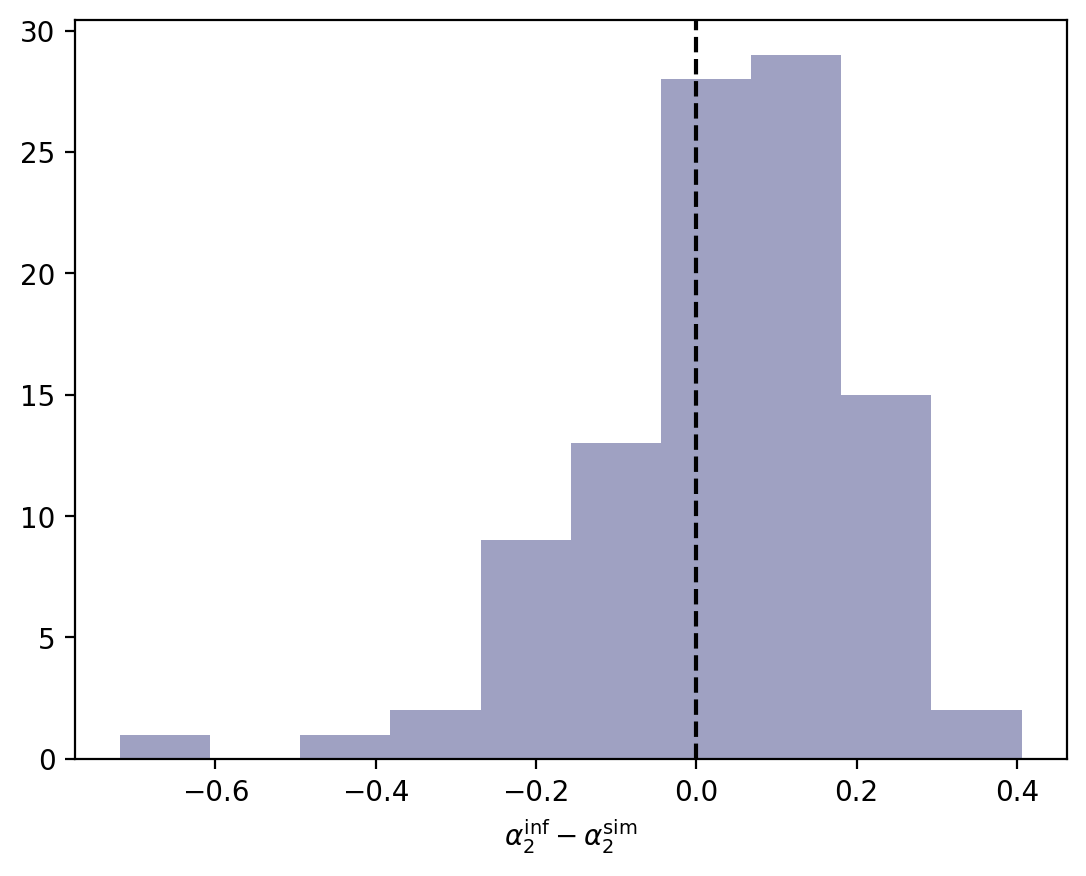

In [70]:
# PPC
delta_ng = nongaussian_inf - nongaussian_sim
p_upper = np.mean(delta_ng <= 0)  # P(sim >= inf)
p_two = 2 * min(np.mean(delta_ng >= 0), np.mean(delta_ng <= 0))

print(f'upper p-value =\t\t{p_upper:5}')
print(f'two-sided p-value =\t{p_two:5}')

plt.hist(delta_ng, bins=10, color=cmap(0.2), label='sim', alpha=0.5)
plt.axvline(x=0, color='k', ls='--')
plt.xlabel(r'$\alpha_2^{\text{inf}} - \alpha_2^{\text{sim}}$');

### Negative (Left) Tail

0.004382572828048466


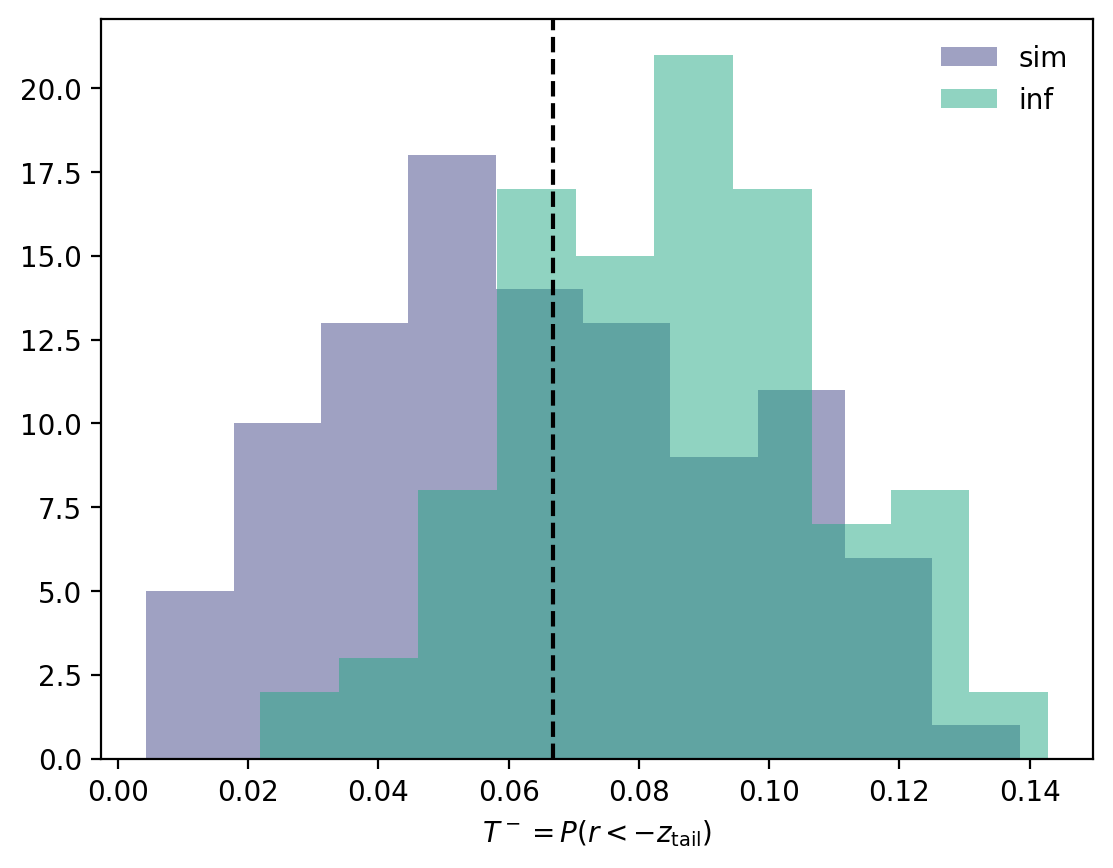

In [71]:
z_tail = 1.5
T0 = stats.norm.sf(z_tail)

tail_neg_inf = np.mean(r_inf_samples < -z_tail, axis=0)
tail_neg_sim = np.mean(r_sim_samples < -z_tail, axis=0)
print(tail_neg_sim.min()) # should be non-zero

plt.hist(tail_neg_sim, bins=10, label='sim', alpha=0.5, color=cmap(0.2))
plt.hist(tail_neg_inf, bins=10, label='inf', alpha=0.5, color=cmap(0.6))
plt.axvline(x=T0, color='k', ls='--')
plt.legend(frameon=False)

plt.xlabel(r'$T^-=P(r < -z_\text{tail})$');

In [72]:
r_inf_samples.shape

(3879, 100)

p-value = 0.34


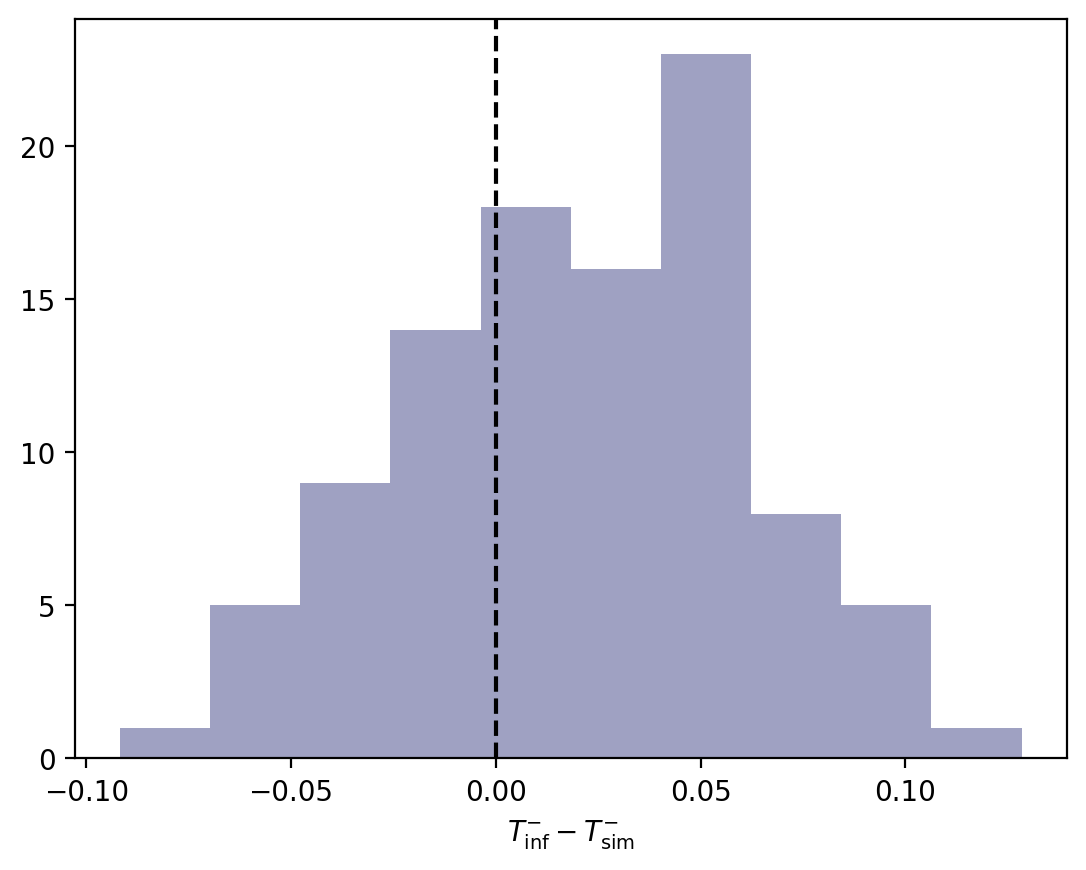

In [73]:
# PPC
delta_neg = tail_neg_inf - tail_neg_sim
p_neg = np.mean(delta_neg <= 0)  # small if inferred has excess negative tail

print(f'p-value ={p_neg:5}')

plt.hist(delta_neg, bins=10, color=cmap(0.2), label='sim', alpha=0.5)
plt.axvline(x=0, color='k', ls='--')
plt.xlabel(r'$T^{-}_{\text{inf}} - T^{-}_{\text{sim}}$');

In [74]:
# np.savez(
#     "delta_neg_good.npz",
#     delta_neg=delta_neg,
# )

# np.savez(
#     "delta_neg_bad.npz",
#     delta_neg=delta_neg,
# )

### Positive (right) Tail

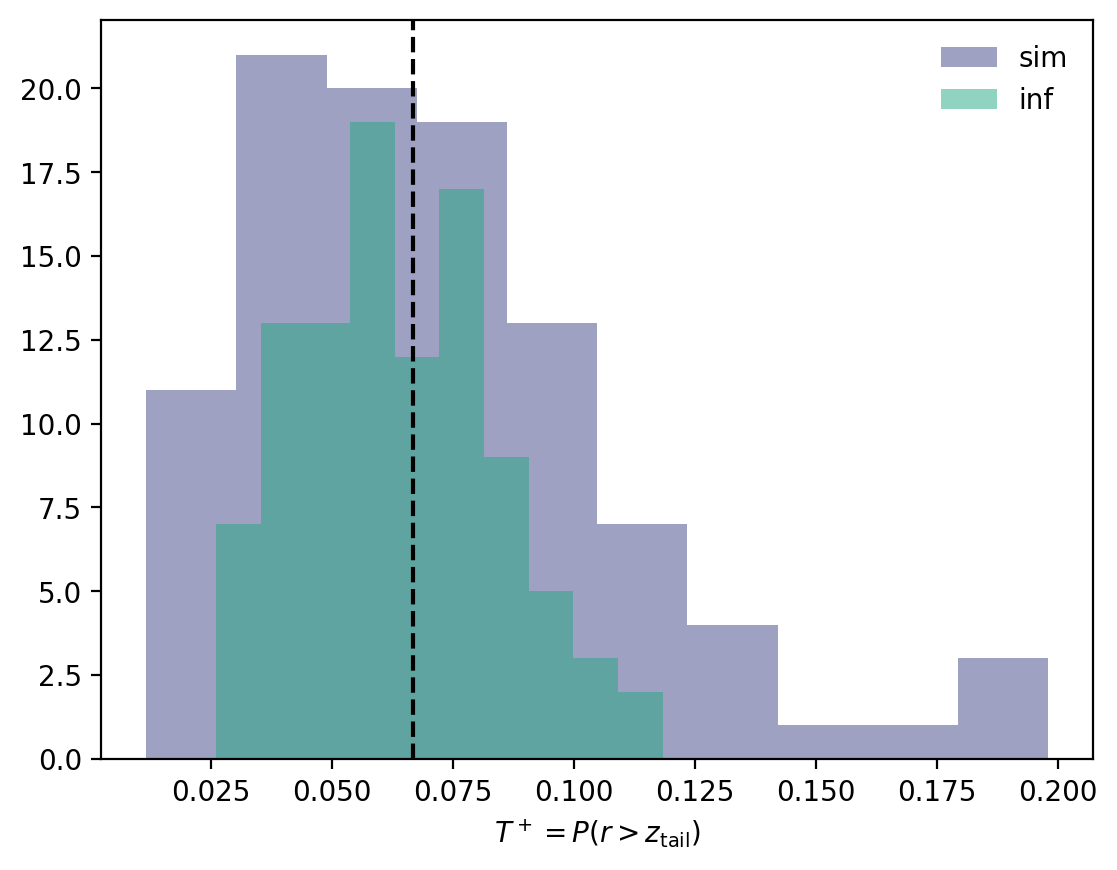

In [75]:
tail_pos_inf = np.mean(r_inf_samples > z_tail, axis=0)
tail_pos_sim = np.mean(r_sim_samples > z_tail, axis=0)

plt.hist(tail_pos_sim, bins=10, label='sim', alpha=0.5, color=cmap(0.2))
plt.hist(tail_pos_inf, bins=10, label='inf', alpha=0.5, color=cmap(0.6))
plt.axvline(x=T0, color='k', ls='--')
plt.legend(frameon=False)

plt.xlabel(r'$T^+=P(r > z_\text{tail})$');

p-value =	 0.49


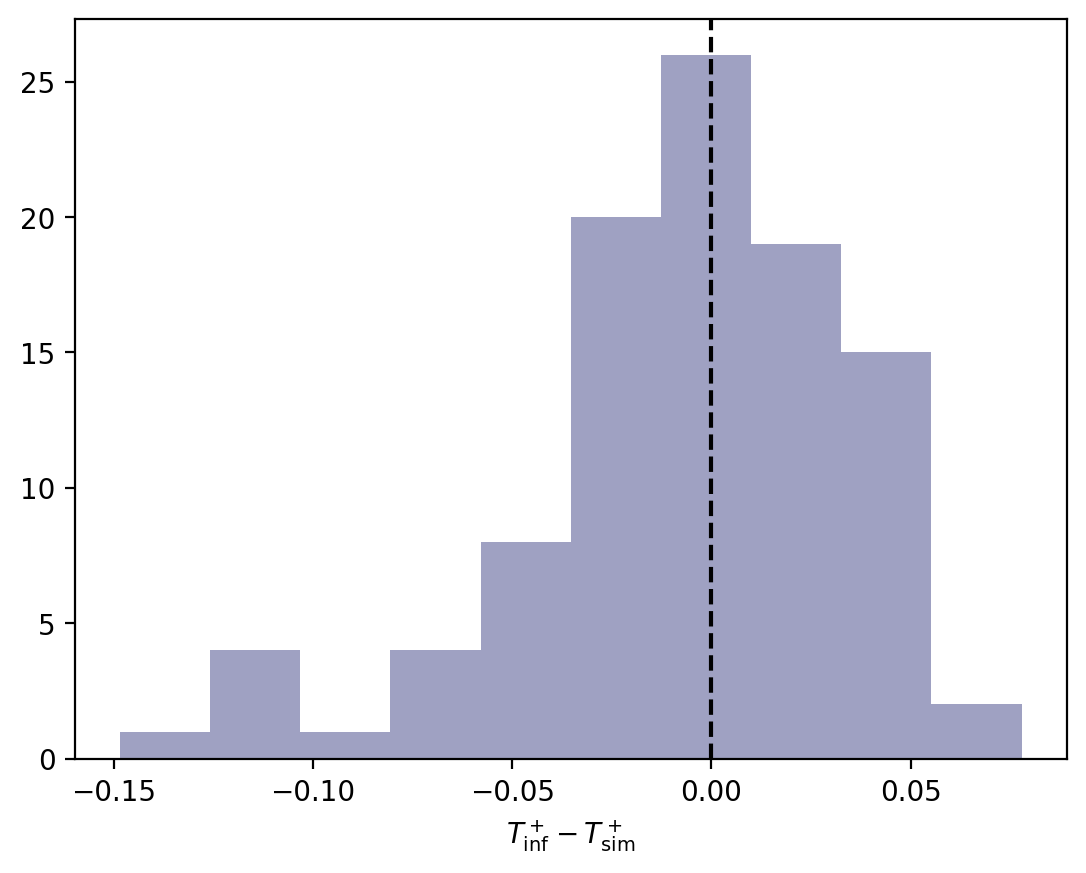

In [76]:
# PPC
delta_pos = tail_pos_inf - tail_pos_sim
p_pos = np.mean(delta_pos >= 0)  # small if inferred has deficit positive tail

print(f'p-value =\t{p_pos:5}')

plt.hist(delta_pos, bins=10, color=cmap(0.2), label='sim', alpha=0.5)
plt.axvline(x=0, color='k', ls='--')
plt.xlabel(r'$T^+_{\text{inf}} - T^+_{\text{sim}}$');

In [77]:
# np.savez(
#     "delta_tail_good.npz",
#     delta_tail=delta_tail,
# )

# np.savez(
#     "delta_neg_bad.npz",
#     delta_pos=delta_pos,
# )

# Automated Workflow

## 0. Fit parameters

In [78]:
n_theta = 256
M = 3

data = {
    "tk": tk,
    "yk": yk,
}

prior_kwargs = dict(
    sigma_omega=1.0,
    alpha_D=1.0,
    Dtheta_mode=2.0,
    alpha_R=1.0,
)

optimizer_kwargs = dict(
    method="BFGS",
    options=dict(
        maxiter=500, 
        gtol=1e-4,
    ),
)

out = HPJ.run_added_noise_fit_jax(
    data,
    R_add,
    M,
    rng,
    n_theta=n_theta,
    param0=None,
    prior_kwargs=prior_kwargs,
    optimizer_kwargs=optimizer_kwargs,
    compute_uncertainty=True,
    hessian_method='direct',
)

In [79]:
out['row']

{'omega': 51.881854579142605,
 'Dtheta': 2.301131238886679,
 'R_eff': 1044703.3572826603,
 'lnDtheta': 0.8334008450141926,
 'lnR': 13.85924353445369,
 'M': 3,
 'A0': -1.6989099859378614,
 'A1': 902.7899398704676,
 'A2': 164.0309361263311,
 'A3': 59.435362239914596,
 'B0': 0.0,
 'B1': 0.0,
 'B2': -249.34831238425397,
 'B3': 12.759272734673385,
 'R_add': 1000000.0,
 'success': True,
 'fun': 33580.04914013187,
 'nfev': 83,
 'njev': 83,
 'nit': 79,
 'message': 'Optimization terminated successfully.',
 'omega_se': 0.5156603813073762,
 'lnDtheta_se': 0.18906134269029182,
 'lnR_se': 0.024087898294314777,
 'Dtheta_mult_se': 1.2081150592378405,
 'R_eff_mult_se': 1.024380355219453,
 'hessian_method': 'direct',
 'hessian_min_eig': 0.0006192246673013698,
 'hessian_max_eig': 1862.9331659218492,
 'hessian_condition': 3008493.143596265}

## 1. Draw posterior parameter samples

In [80]:
rng = np.random.default_rng(seed=12345)

# 1. Draw posterior parameter samples
x_samples = HP.sample_laplace_parameters(
    out["fit"]["x"],
    out["cov"]["cov"],
    n_samples=n_param_samples,
    rng=rng,
)

## 2. Sample inferred and simulated phases

In [81]:
phases = HP.sample_phase_populations(
    x_samples,
    out["fit_data"],
    out["priors"],
    M=M,
    rng=rng,
    n_phase_per_param=2,
    n_theta=n_theta,
)

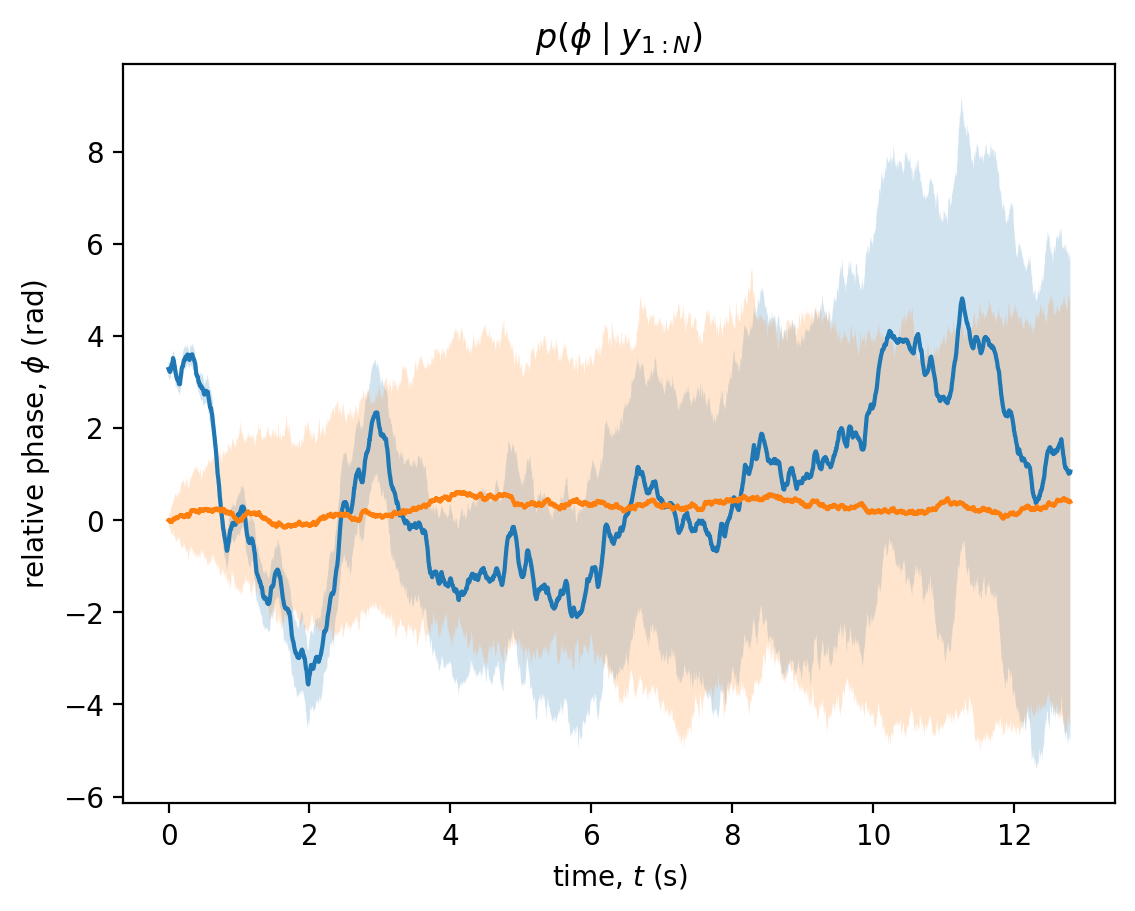

In [82]:
phi_inf_samples = np.reshape(phases["phi_inf"], (N, n_samples))
phi_inf_mean = np.mean(phi_inf_samples, axis=1)
phi_inf_lo = np.percentile(phi_inf_samples, 25, axis=1)
phi_inf_hi = np.percentile(phi_inf_samples, 75, axis=1)

phi_sim_samples = np.reshape(phases["phi_sim"], (N, n_samples))
phi_sim_mean = np.mean(phi_sim_samples, axis=1)
phi_sim_lo = np.percentile(phi_sim_samples, 25, axis=1)
phi_sim_hi = np.percentile(phi_sim_samples, 75, axis=1)

plt.plot(tk, phi_inf_mean)
plt.fill_between(tk, phi_inf_lo, phi_inf_hi, alpha=0.2)

plt.plot(tk, phi_sim_mean)
plt.fill_between(tk, phi_sim_lo, phi_sim_hi, alpha=0.2)

plt.xlabel('time, $t$ (s)')
plt.ylabel(r'relative phase, $\phi$ (rad)')
plt.title(r'$p(\phi \mid y_{1:N})$');

## 3. Compute lower-tail statistics and p-value

In [83]:
intervals = HP.phase_interval_statistics(
        phases,
        D_ref=np.exp(out["fit"]["x"][1]),
    )

In [84]:
z_tail = 1.5
T0 = stats.norm.sf(z_tail)

tail_ppc = HP.lower_tail_interval_ppc(
    intervals,
    z_tail=z_tail,
    alpha=0.05,
)
print(tail_ppc['tail_p_value'])

0.4411764705882353


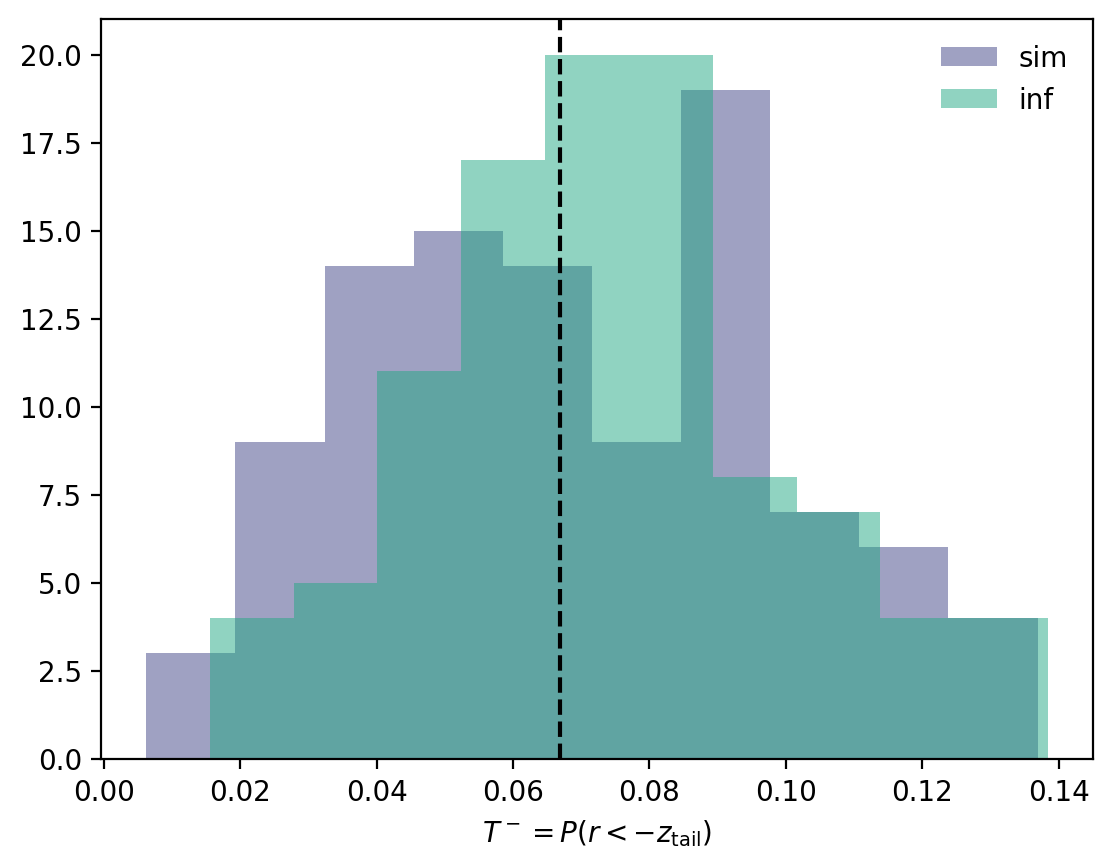

In [85]:
plt.hist(tail_ppc['tail_T_sim'], bins=10, label='sim', alpha=0.5, color=cmap(0.2))
plt.hist(tail_ppc['tail_T_inf'], bins=10, label='inf', alpha=0.5, color=cmap(0.6))
plt.axvline(x=T0, color='k', ls='--')
plt.legend(frameon=False)

plt.xlabel(r'$T^-=P(r < -z_\text{tail})$');

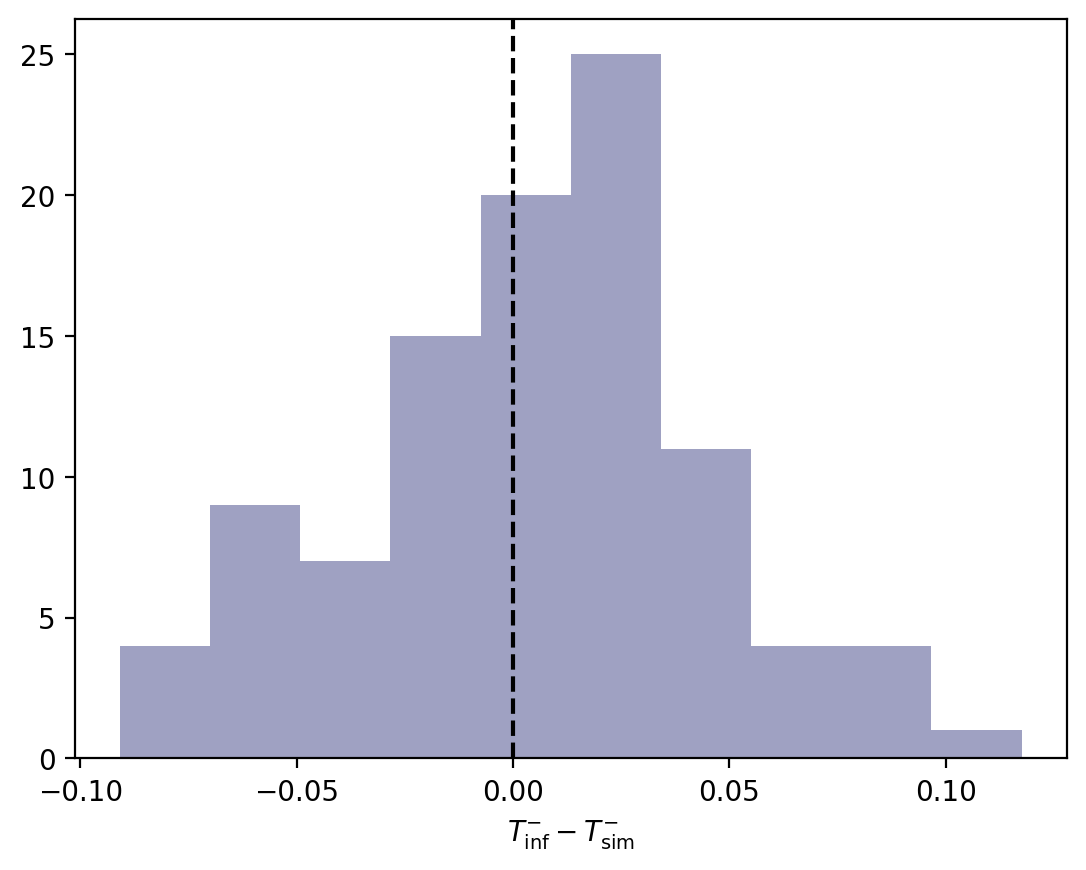

In [86]:
plt.hist(tail_ppc['tail_delta'], bins=10, color=cmap(0.2), label='sim', alpha=0.5)
plt.axvline(x=0, color='k', ls='--')
plt.xlabel(r'$T^{-}_{\text{inf}} - T^{-}_{\text{sim}}$');

##  1-3. Wrapped together

In [87]:
rng = np.random.default_rng(seed=12345)

ppc = HP.run_interval_ppcs(
    out,
    rng=rng,
    n_param_samples=50,
    n_phase_per_param=2,
    n_theta=n_theta,
    z_tail=1.5,
    alpha=0.05,
)

In [88]:
print(ppc["msd_p_value"], ppc["msd_passes"])
print(ppc["tail_p_value"], ppc["tail_passes"])
print(ppc["ng_p_value"], ppc["ng_passes"])

0.9215686274509803 True
0.4411764705882353 True
0.49019607843137253 True


## MSD

In [89]:
ppc.keys()

dict_keys(['lag', 'tau', 'x_samples', 'phases', 'intervals', 'msd_p_value', 'msd_passes', 'msd_alpha', 'msd_alternative', 'msd_delta_mean', 'msd_delta_median', 'msd_delta_q25', 'msd_delta_q75', 'msd_T_inf', 'msd_T_sim', 'msd_delta', 'tail_p_value', 'tail_passes', 'tail_alpha', 'tail_alternative', 'tail_delta_mean', 'tail_delta_median', 'tail_delta_q25', 'tail_delta_q75', 'tail_z', 'tail_T_inf', 'tail_T_sim', 'tail_delta', 'ng_p_value', 'ng_passes', 'ng_alpha', 'ng_alternative', 'ng_delta_mean', 'ng_delta_median', 'ng_delta_q25', 'ng_delta_q75', 'ng_T_inf', 'ng_T_sim', 'ng_delta'])

(array([10., 22., 22., 17., 20.,  2.,  3.,  3.,  0.,  1.]),
 array([0.89910337, 1.27270516, 1.64630695, 2.01990874, 2.39351052,
        2.76711231, 3.1407141 , 3.51431589, 3.88791768, 4.26151947,
        4.63512125]),
 <BarContainer object of 10 artists>)

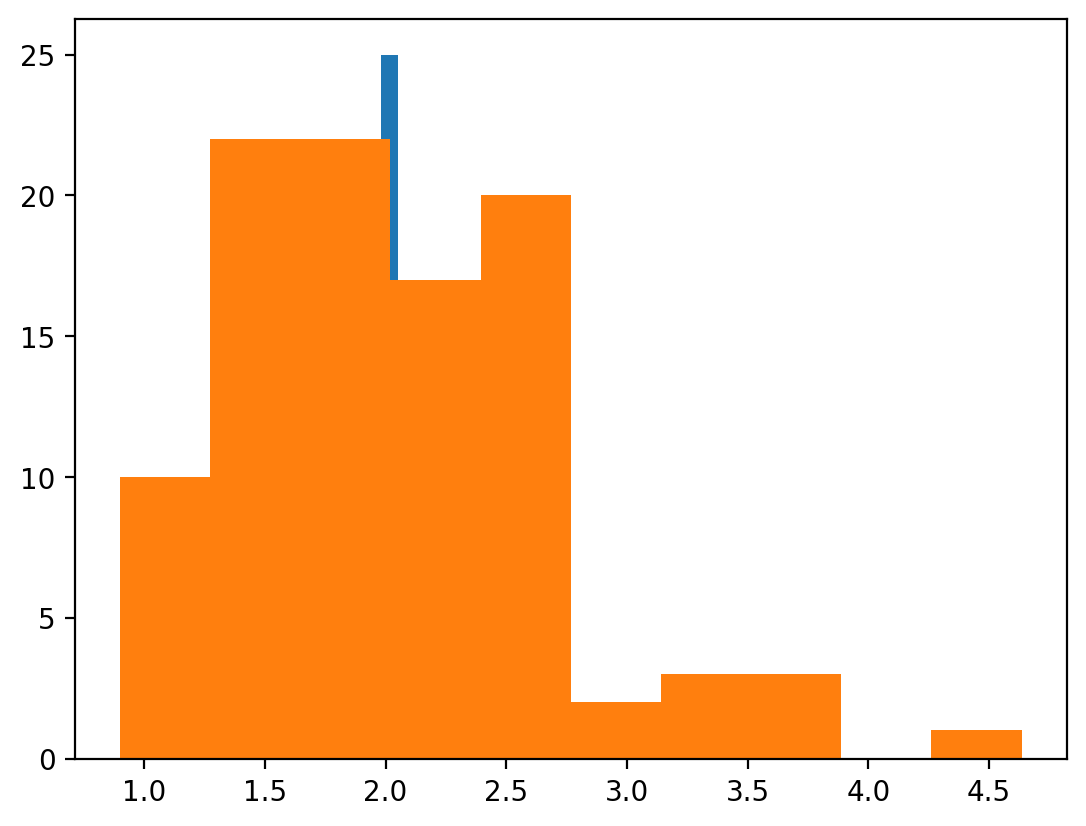

In [90]:
plt.hist(ppc['msd_T_inf'])
plt.hist(ppc['msd_T_sim'])